In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.special import kv, gamma
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.linalg import cholesky, cho_solve ,solve_triangular
from scipy.interpolate import Rbf
from mpl_toolkits.mplot3d import Axes3D  
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import interp1d
import pandas as pd
from scipy.interpolate import LinearNDInterpolator
import itertools
import warnings
from scipy.stats import qmc
from scipy.stats import wilcoxon
import matplotlib.tri as tri
from matplotlib.path import Path
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve
import time
import matplotlib as mpl
from IPython.display import clear_output
import random
import matplotlib.patches as patches
from scipy.sparse import coo_matrix
from joblib import Parallel, delayed
from IPython.display import clear_output
rng = np.random.RandomState(42)
warnings.filterwarnings("ignore")

In [ ]:


# -----------------------------
# 1️⃣ Partition utilities
# -----------------------------
def divide_bounds(bounds, n_parts=2, mode='grid', axis=0):
    """
    Subdivides a bounding box into multiple smaller regions.
    
    Variables:
    - bounds: (n_dim, 2) array of min/max values for each dimension.
    - n_parts: Number of divisions per dimension (grid) or total (axis).
    - mode: 'grid' for full factorial split, 'axis' for splitting one dimension.
    - axis: The specific dimension index to split if mode is 'axis'.
    """
    bounds = np.array(bounds, dtype=float)
    n_dim = bounds.shape[0]
    n_parts = int(n_parts)
    
    # Create division points for every dimension
    grid_points = [np.linspace(bounds[d,0], bounds[d,1], n_parts+1) for d in range(n_dim)]
    region_bounds = []
    
    if n_parts == 1:
        return [bounds], grid_points
    
    # mode='grid' creates (n_parts^n_dim) small hyper-rectangles
    if mode == 'grid':
        for idx in itertools.product(range(n_parts), repeat=n_dim):
            b = bounds.copy()
            for d in range(n_dim):
                b[d,0] = grid_points[d][idx[d]]
                b[d,1] = grid_points[d][idx[d]+1]
            region_bounds.append(b)
            
    # mode='axis' splits only along a single chosen dimension
    elif mode == 'axis':
        for i in range(n_parts):
            b = bounds.copy()
            b[axis,0] = grid_points[axis][i]
            b[axis,1] = grid_points[axis][i+1]
            region_bounds.append(b)
            
    return region_bounds, grid_points

def region_index(X, grid_points):
    """
    Identifies which grid cell a specific point X belongs to.
    
    Variables:
    - X: Input coordinates.
    - grid_points: The split points generated by divide_bounds.
    """
    X = np.atleast_2d(X)
    n_dim = X.shape[1]
    n_parts = len(grid_points[0])-1
    indices = []
    
    # Find bin index for each dimension using NumPy digitize
    for d in range(n_dim):
        idx_d = np.digitize(X[:,d], grid_points[d][1:-1], right=True)
        idx_d = np.clip(idx_d, 0, n_parts-1)
        indices.append(idx_d)
        
    multi_idx = np.vstack(indices).T
    # Convert multi-dimensional index to a single flat integer
    flat_idx = np.ravel_multi_index(multi_idx.T, dims=[n_parts]*n_dim)
    return flat_idx

# -----------------------------
# 2️⃣ Matern kernel
# -----------------------------
def matern_kernel(X1, X2, l=1.0, nu=2.5):
    """
    Computes the Matérn covariance matrix between two sets of points.
    
    Variables:
    - l: Length-scale (how far the influence of a point spreads).
    - nu: Smoothness parameter (0.5=rough, 1.5=medium, 2.5=smooth).
    - r: Euclidean distance between normalized points.
    """
    X1, X2 = np.atleast_2d(X1), np.atleast_2d(X2)
    r = cdist(X1/l, X2/l)
    
    if nu == 0.5: # Absolute Exponential Kernel
        return np.exp(-r)
    elif nu == 1.5:
        sqrt3_r = np.sqrt(3) * r
        return (1 + sqrt3_r) * np.exp(-sqrt3_r)
    elif nu == 2.5: # Standard for many BO tasks
        sqrt5_r = np.sqrt(5) * r
        return (1 + sqrt5_r + 5/3 * r**2) * np.exp(-sqrt5_r)
    else: # General case using Bessel functions
        sqrt_2nu_r = np.sqrt(2 * nu) * r
        K = (2**(1-nu)/gamma(nu)) * (sqrt_2nu_r**nu) * kv(nu, sqrt_2nu_r)
        K[r == 0] = 1.0 # Ensure diagonal is exactly 1.0
        return K



# -----------------------------
# 3️⃣ GP fast prediction
# -----------------------------
def gp_predict_fast(x_train, x_test, kernel_func, L, alpha, **kernel_args):
    """
    Calculates the mean (mu) and standard deviation (sigma) for new points.
    
    Variables:
    - L: Cholesky decomposition of the training covariance matrix.
    - alpha: Pre-calculated weights (L^-T * L^-1 * y).
    - v: Intermediate step for variance calculation (L^-1 * K_test_train).
    """
    K_s = kernel_func(x_train, x_test, **kernel_args)
    mu = K_s.T @ alpha # Predicted mean
    
    # Variance calculation using the Cholesky factor for speed
    v = solve_triangular(L, K_s, lower=True)
    var = 1.0 - np.sum(v**2, axis=0) # Standard GP variance formula
    return mu.flatten(), np.sqrt(np.maximum(var, 0.0))

# -----------------------------
# 4️⃣ Sigma estimator
# -----------------------------
def sigma_estimator(X, y, kernel, **kernel_args):
    """
    Maximum Likelihood style estimator for the local signal scale.
    
    Variables:
    - jitter: Small value added to the diagonal for numerical stability.
    - K_reg: Regularized covariance matrix.
    - sigma2: Estimated variance (y^T * K^-1 * y / N).
    """
    N = len(X)
    K = kernel(X, X, **kernel_args)
    
    # Adaptive jitter: prevents matrix inversion errors in flat regions
    trace_K = np.trace(K)
    jitter = 1e-6 * trace_K / N  
    
    try:
        K_reg = K + jitter * np.eye(N)
        L = cholesky(K_reg, lower=True)
        alpha = cho_solve((L, True), y)
        sigma2 = y @ alpha / N # Estimated signal scale
        
        if sigma2 > 0 and not np.isnan(sigma2):
            return np.sqrt(sigma2)
    except np.linalg.LinAlgError:
        pass
    
    # Fallback if the matrix is too ill-conditioned
    return np.std(y)



# -----------------------------
# 5️⃣ Partition tree
# -----------------------------

def partition_tree(f, N, initial_bounds, kernel, kernel_args, sigma_estimator, iter_max=3, figg=False):
    """
    Builds an adaptive grid by splitting regions with high variance ratios.
    
    Variables:
    - f: Objective function to sample.
    - queue: List of regions waiting to be evaluated for a split.
    - ratio: The max_sigma / min_sigma of child regions.
    - threshold: If ratio > threshold, the function is 'non-stationary' enough to split.
    """
    n_dim = initial_bounds.shape[0]
    # Initial random sampling to understand the surface
    X = np.random.uniform(initial_bounds[:,0], initial_bounds[:,1], (max(N, 5), n_dim))
    y = f(X).flatten()
    
    root_sigma = sigma_estimator(X, y, kernel, **kernel_args)
    queue = [(initial_bounds, root_sigma, 0)]
    iterations_history = {i: [] for i in range(iter_max+1)}
    iterations_history[0].append(initial_bounds)
    final_leaves = []
    threshold = 1.4

    while queue:
        curr_b, curr_s, depth = queue.pop(0)
        
        if depth >= iter_max:
            final_leaves.append(curr_b)
            continue
        
        splits_info = []
        # Test splitting along X and Y axes
        for axis in [0, 1]:
            children, grid_pts = divide_bounds(curr_b, n_parts=2, mode='axis', axis=axis)
            idx = np.digitize(X[:, axis], grid_pts[axis][1:-1], right=True)
            idx = np.clip(idx, 0, len(children)-1)

            child_sigmas = []
            for r in range(len(children)):
                mask = (idx == r)
                # Estimate sigma for each child if enough data points exist
                if np.sum(mask) >= 3:
                    sig_child = sigma_estimator(X[mask], y[mask], kernel, **kernel_args)
                else:
                    sig_child = curr_s
                child_sigmas.append(sig_child)

            splits_info.append({
                'axis': axis,
                'children': children,
                'sigmas': child_sigmas,
                'max_sigma': max(child_sigmas)
            })

        # Pick the axis that reveals the most variance difference
        best_split = splits_info[0] if splits_info[0]['max_sigma'] >= splits_info[1]['max_sigma'] else splits_info[1]

        s1, s2 = best_split['sigmas']
        ratio = max(s1, s2) / (min(s1, s2) + 1e-12)
        
        # Decision logic: Only split if the children are significantly different
        if ratio > threshold:
            for child_b, child_s in zip(best_split['children'], best_split['sigmas']):
                queue.append((child_b, child_s, depth+1))
                iterations_history[depth+1].append(child_b)
        else:
            final_leaves.append(curr_b)
            for d in range(depth+1, iter_max+1):
                iterations_history[d].append(curr_b)
        # --- Plotting ---
    if figg:
        fig, axes = plt.subplots(1, iter_max + 1, figsize=(20, 5))
        for d, ax in iterations_history.items():
            ax_plot = axes[d]
            ax_plot.set_title(f"Iteration {d}")
            ax_plot.set_xlim(initial_bounds[0])
            ax_plot.set_ylim(initial_bounds[1])
            ax_plot.set_aspect('equal')
    
            for b in iterations_history[d]:
                rect = patches.Rectangle((b[0, 0], b[1, 0]),
                                         b[0, 1] - b[0, 0], b[1, 1] - b[1, 0],
                                         linewidth=2, edgecolor='black', facecolor='none')
                ax_plot.add_patch(rect)
    
            ax_plot.scatter(X[:, 0], X[:, 1], s=10, c='blue', alpha=0.5)
    
        plt.tight_layout()
        plt.show()

    return iterations_history[iter_max]    
# -----------------------------
# 6️⃣ General BO with either partition method
# -----------------------------


def bayesian_optimization_partition(
        x_train, y_train, f_true, bounds,
        kernel_func, kernel_args,
        n_iter=10, partition_method='tree', tree_depth=3,
        noise_var=1e-8, sig=True,
        acq_type='ei', acq_params={},
        n_candidates_per_region=256, 
        sigma_estimator=None,
        n_parts_fixed=2):
    
    x_train = np.atleast_2d(x_train)
    y_train = np.atleast_1d(y_train).flatten()
    n_dim = x_train.shape[1]
    
    # 1️⃣ BUILD PARTITIONS
    if partition_method == 'tree':
        leaves_bounds = partition_tree(
            lambda X: f_true(X), N=1000, initial_bounds=bounds,
            kernel=kernel_func, kernel_args=kernel_args,
            sigma_estimator=sigma_estimator, iter_max=tree_depth
        )
    elif partition_method == 'fixed':
        leaves_bounds, _ = divide_bounds(bounds, n_parts=n_parts_fixed, mode='grid')
    else:
        raise ValueError("Unknown partition_method")
    
    n_regions = len(leaves_bounds)
    region_counter = np.zeros(n_regions, dtype=int)
    sigma_per_region = np.ones(n_regions)
    sampler = qmc.Sobol(d=n_dim, scramble=True)
    
    # Internal Helper: Vectorized Acquisition Computation
    def compute_acq_values(x_eval, region_indices):
        """Calculates AF values for a batch of points, each tied to a region sigma."""
        x_eval = np.atleast_2d(x_eval)
        mu, base_std = gp_predict_fast(x_train, x_eval, kernel_func, L, alpha, **kernel_args)
        
        # Pull the local sigma for each point based on which region it's in
        sig_local = sigma_per_region[region_indices]
        sigma_eff = np.maximum(base_std * sig_local, 1e-15)
        y_best = np.min(y_train)
        
        if acq_type == 'ei':
            xi = acq_params.get('xi', 0.01)
            Z = (y_best - mu - xi) / sigma_eff
            return (y_best - mu - xi) * norm.cdf(Z) + sigma_eff * norm.pdf(Z)
        
        elif acq_type == 'pi':
            xi = acq_params.get('xi', 0.01)
            Z = (y_best - mu - xi) / sigma_eff
            return norm.cdf(Z)
        
        elif acq_type == 'lcb':
            beta = acq_params.get('beta', 2.0)
            return -(mu - beta * sigma_eff) # Negative because we maximize
        
        elif acq_type == 'ts':
            return -(mu + sigma_eff * np.random.randn(len(mu)))
        
        return -mu

    # 2️⃣ MAIN OPTIMIZATION LOOP
    for i in range(n_iter):
        # Update GP Model (Cholesky)
        K_full = kernel_func(x_train, x_train, **kernel_args)
        K_full[np.diag_indices_from(K_full)] += noise_var
        
        jitter = 1e-8
        while True:
            try:
                L = cholesky(K_full + np.eye(len(K_full)) * jitter, lower=True)
                break
            except np.linalg.LinAlgError:
                jitter *= 10
                if jitter > 1e-1: raise np.linalg.LinAlgError("Matrix non-invertible.")
        
        alpha = cho_solve((L, True), y_train)
        
        # Update Local Sigma Estimates
        if sig:
            for r, b in enumerate(leaves_bounds):
                mask = np.all((x_train >= b[:, 0]) & (x_train <= b[:, 1]), axis=1)
                if np.sum(mask) >= 3:
                    sigma_per_region[r] = sigma_estimator(x_train[mask], y_train[mask], kernel_func, **kernel_args)
                else:
                    sigma_per_region[r] = 1.0 # Default/Parent sigma

        # 3️⃣ STEP A: BROAD SOBOL SEARCH
        Xcand_list, region_ids_list = [], []
        for r, b in enumerate(leaves_bounds):
            sobol_pts = sampler.random(n_candidates_per_region)
            # Rescale Sobol to current region bounds
            samples = np.column_stack([sobol_pts[:, d] * (b[d, 1] - b[d, 0]) + b[d, 0] for d in range(n_dim)])
            Xcand_list.append(samples)
            region_ids_list.append(np.full(n_candidates_per_region, r))
            
        X_sobol = np.vstack(Xcand_list)
        R_sobol = np.concatenate(region_ids_list)
        
        acq_sobol = compute_acq_values(X_sobol, R_sobol)
   

 

        # 4️⃣ STEP B: MULTI-START LOCAL REFINEMENT
        n_starts = 3
        top_indices = np.argsort(acq_sobol)[-n_starts:][::-1]
        
        best_refined_x = None
        best_refined_acq = -np.inf
        final_region_idx = None # Track the winning region

        for idx in top_indices:
            x_seed = X_sobol[idx]
            r_idx = R_sobol[idx] # Local region for this seed
            target_bounds = leaves_bounds[r_idx]
            
            def min_obj(x):
                # Critical: use the r_idx specific to this seed
                val = compute_acq_values(x.reshape(1, -1), [r_idx])
                return -float(np.asarray(val).item())

            res = minimize(
                fun=min_obj,
                x0=x_seed,
                bounds=[(target_bounds[d, 0], target_bounds[d, 1]) for d in range(n_dim)],
                method='L-BFGS-B'
            )
            
            current_acq = -res.fun
            if current_acq > best_refined_acq:
                best_refined_acq = current_acq
                best_refined_x = res.x
                final_region_idx = r_idx # Save the winner's region

        # 5️⃣ UPDATE TRAIN SET
        # Use the absolute best found across all starts
        x_next = best_refined_x.reshape(1, -1)
        y_next = f_true(x_next).flatten()
        
        x_train = np.vstack((x_train, x_next))
        y_train = np.append(y_train, y_next)
        
        # Update the counter for the region that actually produced the point
        region_counter[final_region_idx] += 1
        
        # Reset Sobol sampler occasionally to maintain coverage quality
        if i % 5 == 0:
            sampler = qmc.Sobol(d=n_dim, scramble=True)

    return x_train, y_train, sigma_per_region, region_counter









# Mean

In [19]:
def plot_grouped_comparison(histories_dict, n_seeds=30, save_path=None):
    """
    Publication-quality grouped comparison across acquisition functions.
    Includes 95% confidence intervals and improved visual design.
    """

    # -----------------------------
    # Global Style (Paper Ready)
    # -----------------------------
    mpl.rcParams.update({
        "font.family": "serif",
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "legend.fontsize": 10,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 1.1,
        "lines.linewidth": 2.4,
        "figure.dpi": 200,
        "savefig.dpi": 400,
    })

    groups = ['EI', 'PI', 'LCB', 'TS']
    methods = ["Classic BO", "IBO_1","IBO_4", "IBO_P"]

    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 9),
        sharex=True,
        sharey=True,
        constrained_layout=False
    )
    axes = axes.flatten()

    # Professional color palette (colorblind-safe)
    colors = {
        "Classic BO": "#1f77b4",
        "IBO_1": "#d62728",
        "IBO_4": "#ff7f0e",
        "IBO_P": "#2ca02c",
        
    }

    for i, acq in enumerate(groups):
        ax = axes[i]

        for method in methods:
            label = f"{method} - {acq}"
            data = histories_dict[label]

            mean = np.mean(data, axis=0)
            sem = np.std(data, axis=0) / np.sqrt(n_seeds)

            iters = np.arange(len(mean))

            # ---- Main curve ----
            ax.plot(
                iters,
                mean,
                label=method,
                color=colors[method],
                zorder=3
            )

            # ---- 95% Confidence Interval ----
            ax.fill_between(
                iters,
                mean - 1.96 * sem,
                mean + 1.96 * sem,
                color=colors[method],
                alpha=0.18,
                linewidth=0,
                zorder=2
            )

        # Clean panel styling
        ax.set_title(acq, fontweight='bold')
        ax.grid(alpha=0.25)
        ax.set_xlim(left=0)

        if i % 2 == 0:
            ax.set_ylabel("Improvement")

        if i >= 2:
            ax.set_xlabel("Iteration")

    # -----------------------------
    # Global Legend (clean layout)
    # -----------------------------
    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=4,
        frameon=False,
        bbox_to_anchor=(0.5, 1.02)
    )

    fig.suptitle(
        "Impact of Partitioning Across Acquisition Functions",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    # Save as vector for publication
    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", format="pdf", dpi=400)

    plt.show()


def plot_grouped_comparison(histories_dict, n_seeds=30, save_path=None):
    """
    Publication-quality grouped comparison across acquisition functions.
    Includes 95% confidence intervals and improved visual design.
    """

    # -----------------------------
    # Global Style (Paper Ready)
    # -----------------------------
    mpl.rcParams.update({
        "font.family": "serif",
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "legend.fontsize": 10,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 1.1,
        "lines.linewidth": 2.4,
        "figure.dpi": 200,
        "savefig.dpi": 400,
    })

    groups = ['EI', 'PI', 'LCB', 'TS']
    methods = ["Classic BO", "IBO_1","IBO_4", "IBO_P"]

    # Single row with 4 subplots
    fig, axes = plt.subplots(
        1, 4,
        figsize=(16, 5),  # Wider figure for single row
        sharex=True,
        sharey=True,
        constrained_layout=False
    )
    axes = axes.flatten()

    # Professional color palette (colorblind-safe)
    colors = {
        "Classic BO": "#1f77b4",
        "IBO_1": "#d62728",
        "IBO_4": "#ff7f0e",
        "IBO_P": "#2ca02c",
        
    }

    for i, acq in enumerate(groups):
        ax = axes[i]

        for method in methods:
            label = f"{method} - {acq}"
            data = histories_dict[label]

            mean = np.mean(data, axis=0)
            sem = np.std(data, axis=0) / np.sqrt(n_seeds)

            iters = np.arange(len(mean))

            # ---- Main curve ----
            ax.plot(
                iters,
                mean,
                label=method,
                color=colors[method],
                zorder=3
            )

            # ---- 95% Confidence Interval ----
            ax.fill_between(
                iters,
                mean - 1.96 * sem,
                mean + 1.96 * sem,
                color=colors[method],
                alpha=0.18,
                linewidth=0,
                zorder=2
            )

        # Clean panel styling
        ax.set_title(acq, fontweight='bold')
        ax.grid(alpha=0.25)
        ax.set_xlim(left=0)

        # Only set ylabel for first subplot
        if i == 0:
            ax.set_ylabel("Improvement")
        
        # Set xlabel for all subplots
        ax.set_xlabel("Iteration")

        # Add legend only to first subplot
        if i == 0:
            ax.legend(loc='best', frameon=False)

    plt.tight_layout()

    # Save as vector for publication
    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", format="pdf", dpi=400)

    plt.show()



# Mean Ration

In [ ]:
def plot_mean_ratio_across_functions(all_histories, save_path=None):
    """
    Publication-quality plot of mean ratio across functions
    with confidence bands (SEM across functions).
    """

    # --------------------------
    # Global matplotlib settings
    # --------------------------
    mpl.rcParams.update({
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "legend.fontsize": 10,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "lines.linewidth": 2.5,
        "figure.dpi": 200,
        "savefig.dpi": 400,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

    groups = ['EI', 'PI', 'LCB', 'TS']
    n_functions = len(all_histories)
    eps = 0

    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    # Professional color palette
    colors = {
            "c_i1": "#1f77b4",   # blue
            "c_i2": "#d62728",   # red
            "c_ip": "#2ca02c",  # green
            "i1_ip": "#ff7f0e",  # orange
            "i2_ip": "#9467bd"   # purple
            }

    for i, acq in enumerate(groups):
        ax = axes[i]

        ratio_c_i1_list = []
        ratio_c_i2_list = []
        ratio_i1_ip_list = []
        ratio_c_ip_list = []
        ratio_i2_ip_list = []

        # -----------------------------------
        # Compute ratios for each function
        # -----------------------------------
        for histories_dict in all_histories.values():
            classic = histories_dict[f"Classic BO - {acq}"]
            ibo1 = histories_dict[f"IBO_1 - {acq}"]
            ibo2 = histories_dict[f"IBO_4 - {acq}"]
            ibop = histories_dict[f"IBO_P - {acq}"]

            mean_classic = np.mean(classic, axis=0)
            mean_ibo1 = np.mean(ibo1, axis=0)
            mean_ibo2 = np.mean(ibo2, axis=0)
            mean_ibop = np.mean(ibop, axis=0)
            

            ratio_c_i1_list.append(mean_classic / (mean_ibo1 + eps))
            ratio_c_i2_list.append(mean_classic / (mean_ibo2 + eps))
            ratio_c_ip_list.append(mean_classic / (mean_ibop + eps))
            ratio_i1_ip_list.append(mean_ibo1 / (mean_ibop + eps))
            ratio_i2_ip_list.append(mean_ibo2 / (mean_ibop + eps))

        ratio_c_i1 = np.array(ratio_c_i1_list)
        ratio_c_i2 = np.array(ratio_c_i2_list)
        ratio_c_ip = np.array(ratio_c_ip_list)
        ratio_i1_ip = np.array(ratio_i1_ip_list)
        ratio_i2_ip = np.array(ratio_i2_ip_list)

        # -----------------------------------
        # Mean and SEM across functions
        # -----------------------------------
        def mean_sem(x):
            mean = np.mean(x, axis=0)
            sem = np.std(x, axis=0) / np.sqrt(n_functions)
            return mean, sem

        m_c_i1, s1 = mean_sem(ratio_c_i1)
        m_c_i2, s2 = mean_sem(ratio_c_i2)
        m_c_ip, s3 = mean_sem(ratio_c_ip)
        m_i1_ip, s4 = mean_sem(ratio_i1_ip)
        m_i2_ip, s5 = mean_sem(ratio_i2_ip)

        iters = np.arange(len(m_c_i1))
        start_idx = 30  # Python indexing
        iters= iters[start_idx:]

        # Slice all data arrays
        m_c_i1 = m_c_i1[start_idx:]
        s1     = s1[start_idx:]
        
        m_c_i2 = m_c_i2[start_idx:]
        s2     = s2[start_idx:]
        
        m_c_ip = m_c_ip[start_idx:]
        s3     = s3[start_idx:]
        
        m_i1_ip = m_i1_ip[start_idx:]
        s4      = s4[start_idx:]
        
        m_i2_ip = m_i2_ip[start_idx:]
        s5      = s5[start_idx:]

        # -----------------------------------
        # Plot with confidence bands
        # -----------------------------------
        
        ax.plot(iters, m_c_i1, label=r"$Classic / \mathrm{IBO}_1$", color=colors["c_i1"])
        ax.fill_between(iters, m_c_i1 - s1, m_c_i1 + s1,
                        color=colors["c_i1"], alpha=0.2)

        ax.plot(iters, m_c_i2, label=r"$Classic / \mathrm{IBO}_4$", color=colors["c_i2"])
        ax.fill_between(iters, m_c_i2 - s2, m_c_i2 + s2,
                        color=colors["c_i2"], alpha=0.2)

        ax.plot(iters, m_c_ip, label=r"$ Classic / \mathrm{IBO}_P$", color=colors["c_ip"])
        ax.fill_between(iters, m_c_ip - s3, m_c_ip + s3,
                        color=colors["c_ip"], alpha=0.2)

        ax.plot(iters, m_i1_ip, label=r"$ \mathrm{IBO}_1 / \mathrm{IBO}_P$", color=colors["i1_ip"])
        ax.fill_between(iters, m_i1_ip - s4, m_i1_ip + s4,
                        color=colors["i1_ip"], alpha=0.2)

        ax.plot(iters, m_i2_ip, label=r"$ \mathrm{IBO}_4 / \mathrm{IBO}_P$", color=colors["i2_ip"])
        ax.fill_between(iters, m_i2_ip - s5, m_i2_ip + s5,
                        color=colors["i2_ip"], alpha=0.2)

        ax.axhline(1.0, linestyle='--', color='black', alpha=0.6)

        ax.set_title(acq)
        ax.grid(alpha=0.25)

        if i % 2 == 0:
            ax.set_ylabel("Performance Ratio")

        if i >= 2:
            ax.set_xlabel("Iteration")

    # -----------------------------------
    # Shared legend (cleaner look)
    # -----------------------------------
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels,
               loc="upper center",
               ncol=5,
               frameon=False,
               bbox_to_anchor=(0.5, 1.02))

    fig.suptitle("Mean Performance Ratios Across Benchmark Functions",
                 fontsize=15)

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", format="pdf")

    plt.show()


def plot_mean_ratio_across_functions(all_histories, save_path=None):
    """
    Publication-quality plot of mean ratio across functions
    with confidence bands (SEM across functions).
    """

    # --------------------------
    # Global matplotlib settings
    # --------------------------
    mpl.rcParams.update({
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "legend.fontsize": 10,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "lines.linewidth": 2.5,
        "figure.dpi": 200,
        "savefig.dpi": 400,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

    groups = ['EI', 'PI', 'LCB', 'TS']
    n_functions = len(all_histories)
    eps = 0

    # Single row with 4 subplots
    fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharex=True, sharey=True)
    axes = axes.flatten()

    # Professional color palette
    colors = {
            "c_i1": "#1f77b4",   # blue
            "c_i2": "#d62728",   # red
            "c_ip": "#2ca02c",  # green
            "i1_ip": "#ff7f0e",  # orange
            "i2_ip": "#9467bd"   # purple
            }

    for i, acq in enumerate(groups):
        ax = axes[i]

        ratio_c_i1_list = []
        ratio_c_i2_list = []
        ratio_i1_ip_list = []
        ratio_c_ip_list = []
        ratio_i2_ip_list = []

        # -----------------------------------
        # Compute ratios for each function
        # -----------------------------------
        for histories_dict in all_histories.values():
            classic = histories_dict[f"Classic BO - {acq}"]
            ibo1 = histories_dict[f"IBO_1 - {acq}"]
            ibo2 = histories_dict[f"IBO_4 - {acq}"]
            ibop = histories_dict[f"IBO_P - {acq}"]

            mean_classic = np.mean(classic, axis=0)
            mean_ibo1 = np.mean(ibo1, axis=0)
            mean_ibo2 = np.mean(ibo2, axis=0)
            mean_ibop = np.mean(ibop, axis=0)
            

            ratio_c_i1_list.append(mean_classic / (mean_ibo1 + eps))
            ratio_c_i2_list.append(mean_classic / (mean_ibo2 + eps))
            ratio_c_ip_list.append(mean_classic / (mean_ibop + eps))
            ratio_i1_ip_list.append(mean_ibo1 / (mean_ibop + eps))
            ratio_i2_ip_list.append(mean_ibo2 / (mean_ibop + eps))

        ratio_c_i1 = np.array(ratio_c_i1_list)
        ratio_c_i2 = np.array(ratio_c_i2_list)
        ratio_c_ip = np.array(ratio_c_ip_list)
        ratio_i1_ip = np.array(ratio_i1_ip_list)
        ratio_i2_ip = np.array(ratio_i2_ip_list)

        # -----------------------------------
        # Mean and SEM across functions
        # -----------------------------------
        def mean_sem(x):
            mean = np.mean(x, axis=0)
            sem = np.std(x, axis=0) / np.sqrt(n_functions)
            return mean, sem

        m_c_i1, s1 = mean_sem(ratio_c_i1)
        m_c_i2, s2 = mean_sem(ratio_c_i2)
        m_c_ip, s3 = mean_sem(ratio_c_ip)
        m_i1_ip, s4 = mean_sem(ratio_i1_ip)
        m_i2_ip, s5 = mean_sem(ratio_i2_ip)

        iters = np.arange(len(m_c_i1))
        start_idx = 30  # Python indexing
        iters= iters[start_idx:]

        # Slice all data arrays
        m_c_i1 = m_c_i1[start_idx:]
        s1     = s1[start_idx:]
        
        m_c_i2 = m_c_i2[start_idx:]
        s2     = s2[start_idx:]
        
        m_c_ip = m_c_ip[start_idx:]
        s3     = s3[start_idx:]
        
        m_i1_ip = m_i1_ip[start_idx:]
        s4      = s4[start_idx:]
        
        m_i2_ip = m_i2_ip[start_idx:]
        s5      = s5[start_idx:]

        # -----------------------------------
        # Plot with confidence bands
        # -----------------------------------
        #ax.set_yscale("log")
       # ax.set_ylim(0.7, 1.5)
        ax.plot(iters, m_c_i1, label=r"$Classic / \mathrm{IBO}_1$", color=colors["c_i1"])
        ax.fill_between(iters, m_c_i1 - s1, m_c_i1 + s1,
                        color=colors["c_i1"], alpha=0.2)

        ax.plot(iters, m_c_i2, label=r"$Classic / \mathrm{IBO}_4$", color=colors["c_i2"])
        ax.fill_between(iters, m_c_i2 - s2, m_c_i2 + s2,
                        color=colors["c_i2"], alpha=0.2)

        ax.plot(iters, m_c_ip, label=r"$ Classic / \mathrm{IBO}_P$", color=colors["c_ip"])
        ax.fill_between(iters, m_c_ip - s3, m_c_ip + s3,
                        color=colors["c_ip"], alpha=0.2)

        ax.plot(iters, m_i1_ip, label=r"$ \mathrm{IBO}_1 / \mathrm{IBO}_P$", color=colors["i1_ip"])
        ax.fill_between(iters, m_i1_ip - s4, m_i1_ip + s4,
                        color=colors["i1_ip"], alpha=0.2)

        ax.plot(iters, m_i2_ip, label=r"$ \mathrm{IBO}_4 / \mathrm{IBO}_P$", color=colors["i2_ip"])
        ax.fill_between(iters, m_i2_ip - s5, m_i2_ip + s5,
                        color=colors["i2_ip"], alpha=0.2)

        ax.axhline(1.0, linestyle='--', color='black', alpha=0.6)

        ax.set_title(acq)
        ax.grid(alpha=0.25)

        # Only set ylabel for first subplot
        if i == 0:
            ax.set_ylabel("Performance Ratio")
        
        # Set xlabel for all subplots
        ax.set_xlabel("Iteration")

        # Add legend only to first subplot
        if i == 0:
            ax.legend(loc='best', frameon=False, ncol=1)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", format="pdf")

    plt.show()


# Parallel computing

In [1]:


def evaluate_single_bo(seed, objective_function, bounds, configs, n_init, d, n_iter, 
                       kernel_args, noise_var, tree_depth, sigma_estimator, 
                       n_candidates=128):
    """
    Generalized parallel worker to run all BO configurations for a single seed.
    """
    rng = np.random.default_rng()

    # Initial shared design (Assuming uniform bounds across all dimensions)
    a, b = bounds[0][0], bounds[0][1]
    x_train_init = rng.uniform(a, b, (n_init, d))
    y_train_init = objective_function(x_train_init).reshape(-1, 1)

    seed_histories = {}

    for label, partition_method, n_parts_fixed, sig_on, acq_name, params in configs:
        x_out, y_out, _, _ = bayesian_optimization_partition(
            x_train_init.copy(), 
            y_train_init.copy(), 
            objective_function, 
            bounds,
            matern_kernel, 
            kernel_args,
            n_iter=n_iter, 
            partition_method=partition_method,
            tree_depth=tree_depth,
            noise_var=noise_var,
            sig=sig_on,
            acq_type=acq_name,
            acq_params=params,
            n_candidates_per_region=n_candidates,
            sigma_estimator=sigma_estimator,
            n_parts_fixed=n_parts_fixed
        )
        
        # Store "best so far"
        history = np.zeros(n_iter + 1)
        for t in range(n_iter + 1):
            history[t] = np.min(y_out[:n_init + t])
            
        seed_histories[label] = history

    return seed, seed_histories

# Bench Functions

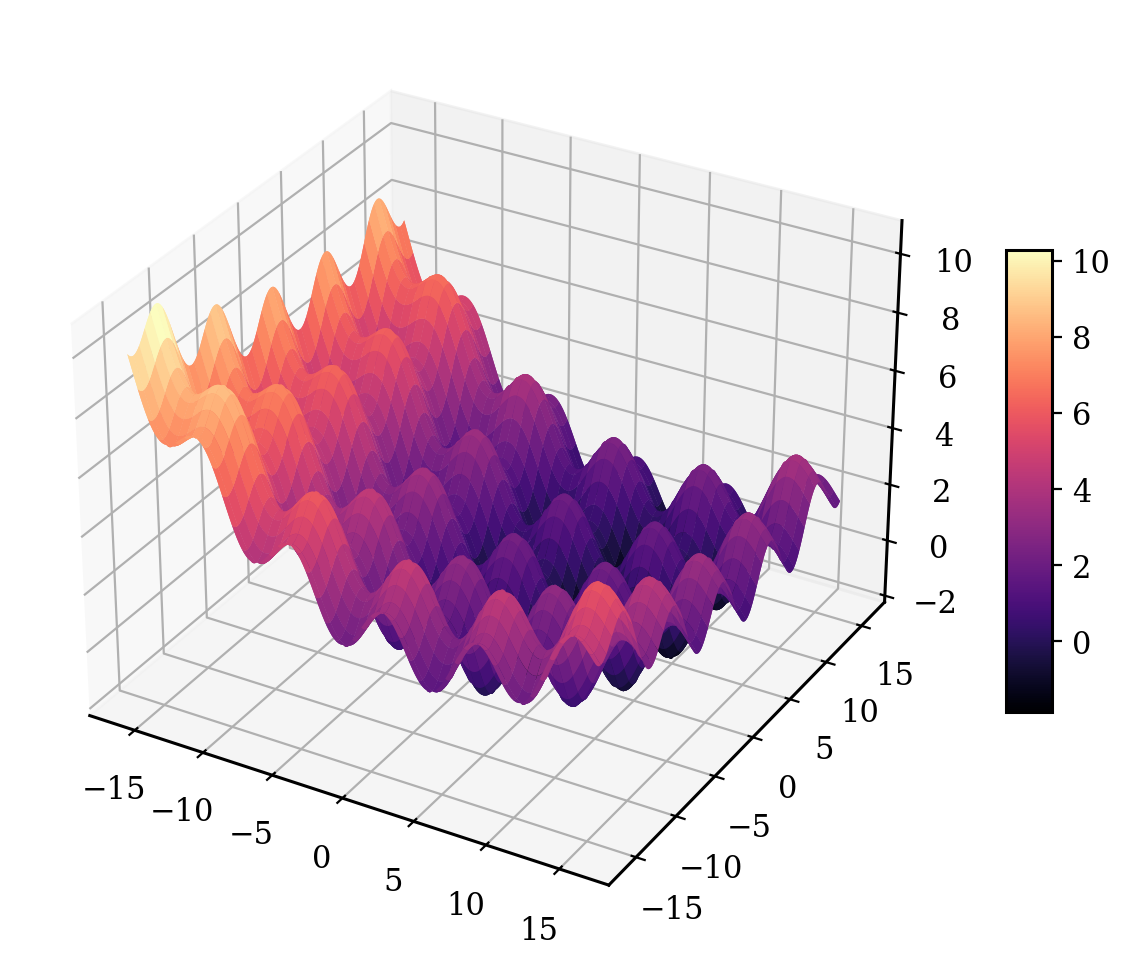

In [ ]:
def f_egg(X):
    x1, x2 = X[:,0], X[:,1]
    return (np.sin(x1) + np.cos(x2) + 0.016*(x1-5)**2 + 0.008*(x2-5)**2)
    
# Domain
x = np.linspace(-16, 16, 200)
y = np.linspace(-16, 16, 200)

X_egg, Y_egg = np.meshgrid(x, y)

# Flatten the grid
XY = np.column_stack([X_egg.ravel(), Y_egg.ravel()])

# Evaluate function
Z = f_egg(XY)

# Reshape back to 2D grid
Z_egg = Z.reshape(X_egg.shape)

# Plot the surface
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X_egg, Y_egg, Z_egg, cmap='magma', linewidth=0, antialiased=True)

surf = ax.plot_surface(
    X_egg, Y_egg, Z_egg,
    cmap='magma',
    linewidth=0,
    antialiased=True
)
plt.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
# Save figure
plt.savefig("f_Eggholder.pdf", bbox_inches="tight", dpi=400)
plt.show()

In [23]:

bounds_egg= np.array([[-16, 16], [-16, 16]])
d = bounds_egg.shape[0]
tree_depth = 3
n_init = 20*d
n_iter = 200
n_seeds = 30

kernel_args = {'l': 6, 'nu': 2.5}
noise_var = 1e-6
# 1. Define all configurations: (Label, n_parts, mode, sig_on, acq_type, params)

configs_egg = [
    # --- EI Group ---
    ("Classic BO - EI", 'fixed', 1,  False, 'ei', {'xi': 0.01}),
    ("IBO_1 - EI",     'fixed' , 1,  True,  'ei', {'xi': 0.01}),
    ("IBO_4 - EI",     'fixed' , 2,  True,  'ei', {'xi': 0.01}),
    ("IBO_P - EI",     'tree' , 2,  True,  'ei', {'xi': 0.01}),
    
    # --- PI Group ---
    ("Classic BO - PI",'fixed',  1,  False, 'pi', {'xi': 0.01}),
    ("IBO_1 - PI",     'fixed' , 1,  True,  'pi', {'xi': 0.01}),
    ("IBO_4 - PI",     'fixed' , 2,  True,  'pi', {'xi': 0.01}),
    ("IBO_P - PI",     'tree' ,  2,  True,  'pi', {'xi': 0.01}),
    
    # --- LCB Group ---
    ("Classic BO - LCB", 'fixed', 1,  False, 'lcb', {'beta': 3.0}),
    ("IBO_1 - LCB",      'fixed', 1,  True,  'lcb', {'beta': 3.0}),
    ("IBO_4 - LCB",     'fixed',  2,  True,  'lcb', {'beta': 3.0}),
    ("IBO_P - LCB",     'tree',    2, True,  'lcb', {'beta': 3.0}),
    
    # --- TS Group ---
    ("Classic BO - TS", 'fixed', 1,  False, 'ts', {}), # Fixed order
    ("IBO_1 - TS",     'fixed',  1,  True,  'ts', {}),
    ("IBO_4 - TS",     'fixed',  2, True,  'ts', {}),
    ("IBO_P - TS",     'tree',   2,  True,  'ts', {})
]




start = time.perf_counter()
print(f"--- Running {n_seeds} Seeds in Parallel for Eggholder ---")

# Run parallel jobs
results_egg = Parallel(n_jobs=-1)(
    delayed(evaluate_single_bo)(
        seed, f_egg, bounds_egg, configs_egg, n_init, d, n_iter, 
        kernel_args, noise_var, tree_depth, sigma_estimator, n_candidates=256
    ) for seed in range(n_seeds)
)

# Reconstruct histories
histories_egg = {c[0]: np.zeros((n_seeds, n_iter + 1)) for c in configs_egg}
for seed, seed_histories in results_egg:
    for label, history in seed_histories.items():
        histories_egg[label][seed, :] = history

end = time.perf_counter()
print(f"Eggholder Execution time: {end - start:.4f} seconds")



--- Running 30 Seeds in Parallel for Eggholder ---
Eggholder Execution time: 149.2046 seconds


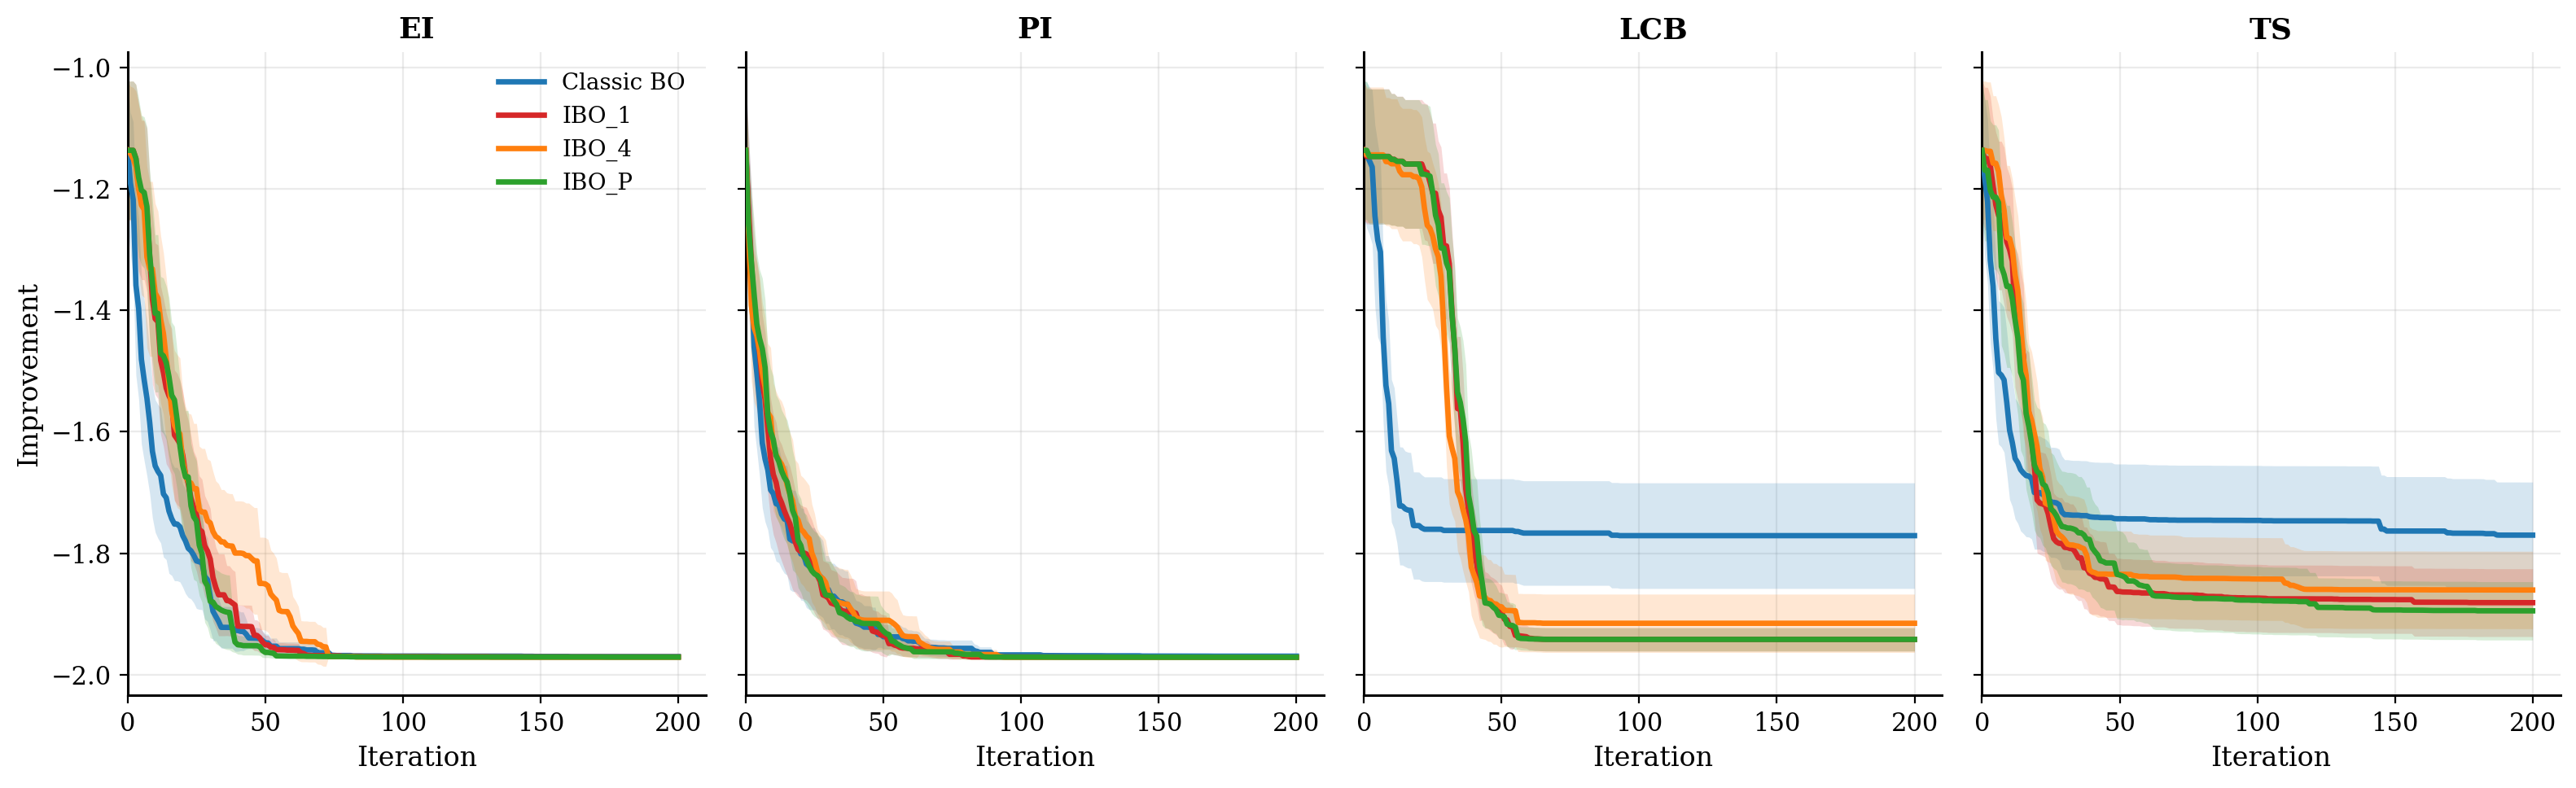

In [24]:
plot_grouped_comparison(histories_egg )

In [25]:


def get_benchmarks():
    f_bench = {}
    target_argmins = {}

    def scale_input(x, low, high):
        # Maps [-1, 1] to [low, high]
        return low + (x + 1.0) * (high - low) / 2.0

    def scale_argmin(orig_argmin, low, high):
        # Maps original point back to [-1, 1] for the target dict
        return 2.0 * (orig_argmin - low) / (high - low) - 1.0

    # Helper decorator to vectorize functions over last axis
    def vectorize_2d(func):
        def wrapper(XY):
            XY = np.asarray(XY)
            # If XY is 1D, make it 2D
            if XY.ndim == 1:
                return func(XY)
            # Reshape to (-1, 2) for computation
            shape_orig = XY.shape[:-1]
            XY_flat = XY.reshape(-1, XY.shape[-1])
            Z_flat = np.array([func(pt) for pt in XY_flat])
            return Z_flat.reshape(shape_orig)
        return wrapper

    # 1. Ackley
    @vectorize_2d
    def ackley(xx):
        xs = scale_input(xx, -32.768, 32.768)
        d = xs.shape[0]
        sum1 = np.sum(xs**2)
        sum2 = np.sum(np.cos(2 * np.pi * xs))
        y = -20 * np.exp(-0.2 * np.sqrt(sum1 / d)) - np.exp(sum2 / d) + 20 + np.exp(1)
        return y + 1.0
    f_bench["Ackley"] = ackley
    target_argmins["Ackley"] = np.array([0.0, 0.0])

    # 2. Schwefel
    @vectorize_2d
    def schwefel(xx):
        xs = scale_input(xx, -500, 500)
        d = xs.shape[0]
        y = 418.9829 * d - np.sum(xs * np.sin(np.sqrt(np.abs(xs))))
        return y + 1.0
    f_bench["Schwefel"] = schwefel
    target_argmins["Schwefel"] = np.array([scale_argmin(420.9687, -500, 500)] * 2)

    # 3. Rastrigin
    @vectorize_2d
    def rastrigin(xx):
        xs = scale_input(xx, -5.12, 5.12)
        d = xs.shape[0]
        y = 10 * d + np.sum(xs**2 - 10 * np.cos(2 * np.pi * xs))
        return y + 1.0
    f_bench["Rastrigin"] = rastrigin
    target_argmins["Rastrigin"] = np.array([0.0, 0.0])

    # 4. Levy
    @vectorize_2d
    def levy(xx):
        xs = scale_input(xx, -10, 10)
        w = 1 + (xs - 1) / 4
        term1 = np.sin(np.pi * w[0])**2
        term3 = (w[-1] - 1)**2 * (1 + np.sin(2 * np.pi * w[-1])**2)
        wi = w[:-1]
        sum_term = np.sum((wi - 1)**2 * (1 + 10 * np.sin(np.pi * wi + 1)**2))
        return term1 + sum_term + term3 + 1.0
    f_bench["Levy"] = levy
    target_argmins["Levy"] = np.array([scale_argmin(1.0, -10, 10)] * 2)

    # 5. Beale
    @vectorize_2d
    def beale(xx):
        xs = scale_input(xx, -4.5, 4.5)
        x, y = xs
        val = (1.5 - x + x*y)**2 + (2.25 - x + x*y**2)**2 + (2.625 - x + x*y**3)**2
        return val + 1.0
    f_bench["Beale"] = beale
    target_argmins["Beale"] = np.array([scale_argmin(3.0, -4.5, 4.5), scale_argmin(0.5, -4.5, 4.5)])

    # 6. Dixon-Price
    @vectorize_2d
    def dixon_price(xx):
        xs = scale_input(xx, -10, 10)
        d = len(xs)
        term1 = (xs[0] - 1)**2
        ii = np.arange(2, d + 1)
        sum_term = np.sum(ii * (2 * xs[1:]**2 - xs[:-1])**2)
        return term1 + sum_term + 1.0
    f_bench["Dixon-Price"] = dixon_price
    x1_orig = 1.0
    x2_orig = 2**(-(2**2 - 2)/2**2)
    target_argmins["Dixon-Price"] = np.array([scale_argmin(x1_orig, -10, 10), scale_argmin(x2_orig, -10, 10)])

    # 7. Griewank
    @vectorize_2d
    def griewank(xx):
        xs = scale_input(xx, -600, 600)
        d = len(xs)
        ii = np.arange(1, d + 1)
        y = np.sum(xs**2 / 4000) - np.prod(np.cos(xs / np.sqrt(ii))) + 1
        return y + 1.0
    f_bench["Griewank"] = griewank
    target_argmins["Griewank"] = np.array([0.0, 0.0])

    # 8. Goldstein-Price
    @vectorize_2d
    def goldpr(xx):
        xs = scale_input(xx, -2, 2)
        x1, x2 = xs
        fact1 = 1 + (x1+x2+1)**2 * (19-14*x1+3*x1**2-14*x2+6*x1*x2+3*x2**2)
        fact2 = 30 + (2*x1-3*x2)**2 * (18-32*x1+12*x1**2+48*x2-36*x1*x2+27*x2**2)
        return (fact1 * fact2 - 3.0) + 1.0
    f_bench["Goldstein-Price"] = goldpr
    target_argmins["Goldstein-Price"] = np.array([scale_argmin(0.0, -2, 2), scale_argmin(-1.0, -2, 2)])

    # 9. Bohachevsky #3
    @vectorize_2d
    def boha3(xx):
        xs = scale_input(xx, -100, 100)
        x1, x2 = xs
        y = x1**2 + 2*x2**2 - 0.3*np.cos(3*np.pi*x1 + 4*np.pi*x2) + 0.3
        return y + 1.0
    f_bench["Bohachevsky"] = boha3
    target_argmins["Bohachevsky"] = np.array([0.0, 0.0])

    # 10. Matyas
    @vectorize_2d
    def matyas(xx):
        xs = scale_input(xx, -100, 100)
        x1, x2 = xs
        y = 0.26 * (x1**2 + x2**2) - 0.48 * x1 * x2
        return y + 1.0
    f_bench["Matyas"] = matyas
    target_argmins["Matyas"] = np.array([0.0, 0.0])

    return f_bench, target_argmins

# Usage
functions_bench, argmin_locations = get_benchmarks()

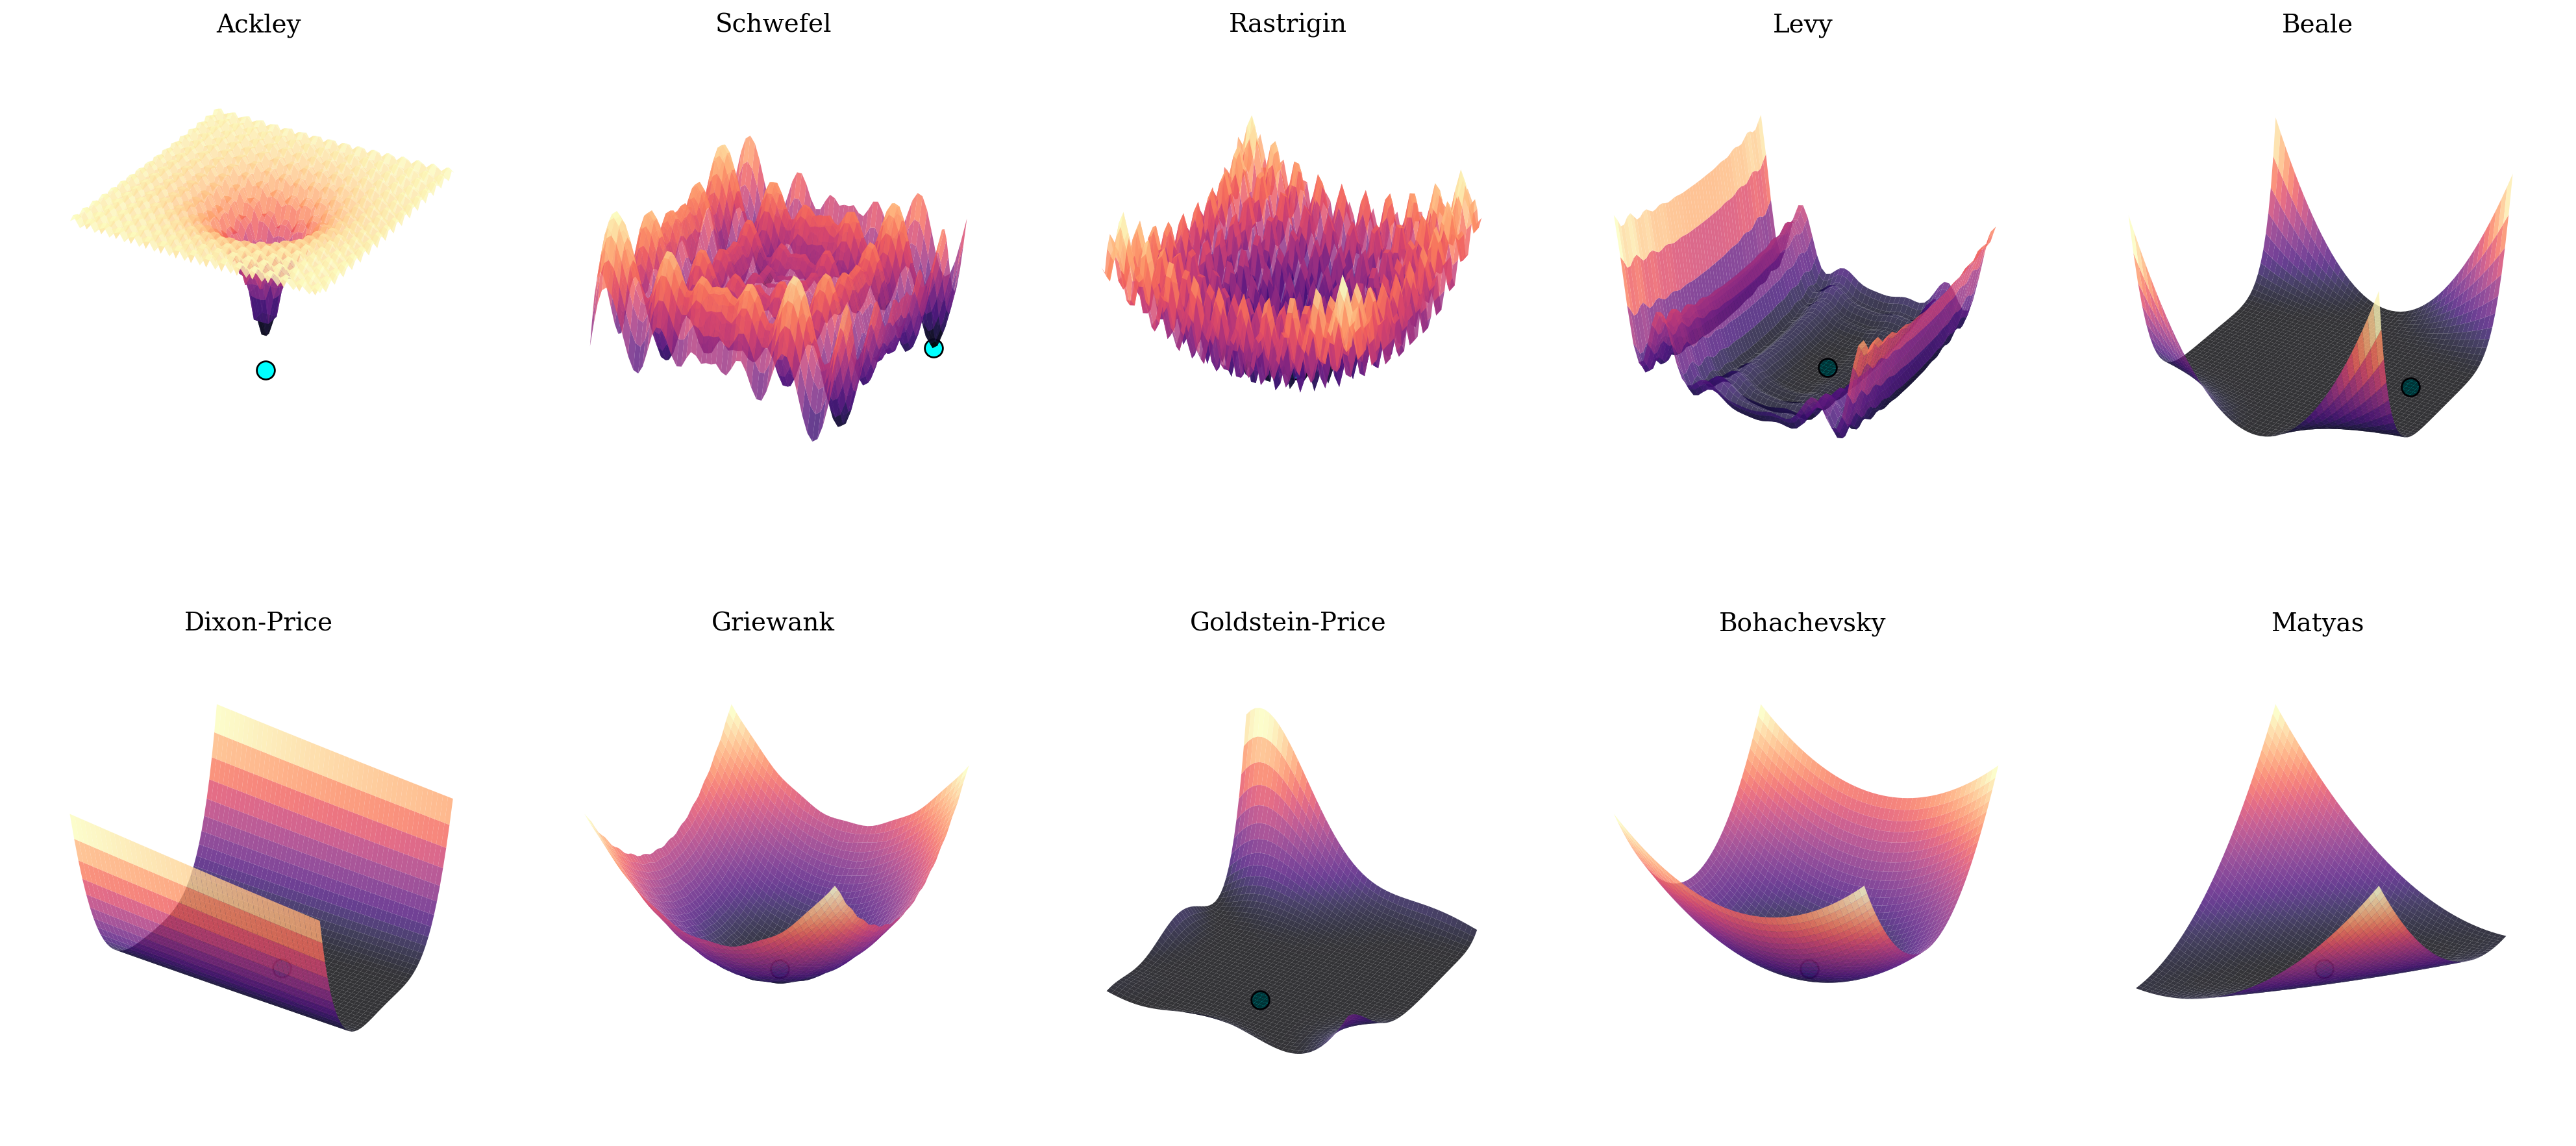

In [26]:


n_functions = len(functions_bench)
rows, cols = 2, 5

fig = plt.figure(figsize=(20, 10))
# Scaling grid to [-1, 1] as requested in the previous step
x_grid = np.linspace(-1, 1, 50)
X, Y = np.meshgrid(x_grid, x_grid)

# We need to reshape the grid so the functions can process it
# Some functions use np.sum(xx**2), so we need the last axis to be the dimension
grid_shape = X.shape
XY = np.stack([X, Y], axis=-1)

for i, (name, func) in enumerate(functions_bench.items()):
    # We flatten the grid to pass it through the function, then reshape back
    # This handles the vectorization for the functions provided
    Z = func(XY)
    
    ax = fig.add_subplot(rows, cols, i + 1, projection='3d')
    surf = ax.plot_surface(X, Y, Z, cmap='magma', alpha=0.8, antialiased=True)
    
    # Access argmin by dictionary key
    target = argmin_locations[name]
    # If the argmin is a single value (for symmetric functions), broadcast it
    if np.isscalar(target):
        target = np.array([target, target])
        
    # Mark the true argmin. Note: the new minimum is 1.0
    ax.scatter(target[0], target[1], 1.0, color='cyan', s=100, edgecolors='black', label='Min', depthshade=False)
    
    ax.set_title(f"{name}", fontsize=14)
    ax.set_axis_off()
   # ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1])
    #ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
#    ax.view_init(elev=30, azim=225) # Standardize view for comparison



plt.tight_layout()
plt.savefig("f_10_homo.pdf", bbox_inches="tight", dpi=400)
plt.show()


Running Ackley (1/10) in Parallel...

Running Schwefel (2/10) in Parallel...

Running Rastrigin (3/10) in Parallel...

Running Levy (4/10) in Parallel...

Running Beale (5/10) in Parallel...

Running Dixon-Price (6/10) in Parallel...

Running Griewank (7/10) in Parallel...

Running Goldstein-Price (8/10) in Parallel...

Running Bohachevsky (9/10) in Parallel...

Running Matyas (10/10) in Parallel...
Benchmark Execution time: 1739.9555 seconds


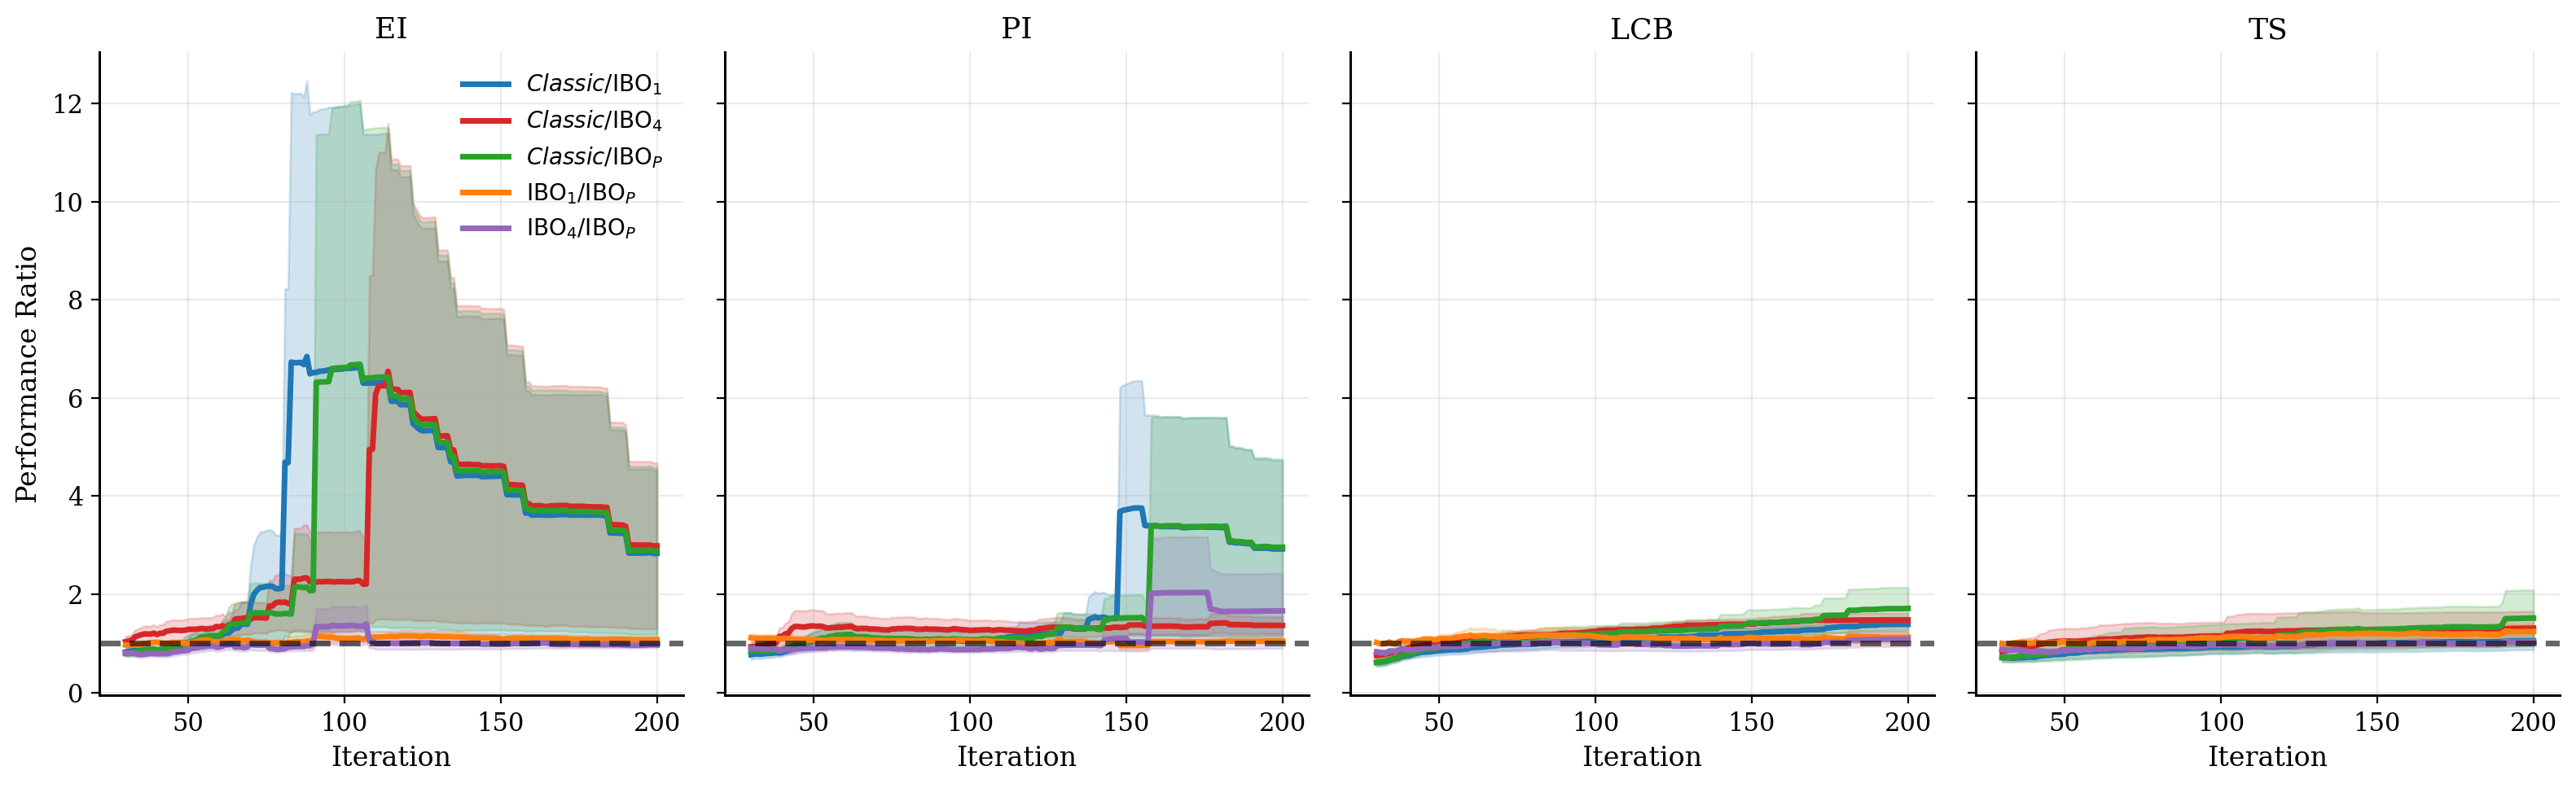

In [27]:


bounds_bench = np.array([[-1, 1], [-1, 1]])
d = bounds_bench.shape[0]
tree_depth = 3
n_init = 20*d
n_iter = 200
n_seeds = 30

kernel_args = {'l': 0.4, 'nu': 2.5}
noise_var = 1e-6

# 1. Define all configurations: (Label, n_parts, sig_on, acq_type, params)
configs_bench = [
    # --- EI Group ---
    ("Classic BO - EI", 'fixed', 1,  False, 'ei', {'xi': 0.05}),
    ("IBO_1 - EI",     'fixed' , 1,  True,  'ei', {'xi': 0.05}),
    ("IBO_4 - EI",     'fixed' , 2,  True,  'ei', {'xi': 0.05}),
    ("IBO_P - EI",     'tree' , 2,  True,  'ei', {'xi': 0.05}),
    
    # --- PI Group ---
    ("Classic BO - PI",'fixed',  1,  False, 'pi', {'xi': 0.05}),
    ("IBO_1 - PI",     'fixed' , 1,  True,  'pi', {'xi': 0.05}),
    ("IBO_4 - PI",     'fixed' , 2,  True,  'pi', {'xi': 0.05}),
    ("IBO_P - PI",     'tree' ,  2,  True,  'pi', {'xi': 0.05}),
    
    # --- LCB Group ---
    ("Classic BO - LCB", 'fixed', 1,  False, 'lcb', {'beta': 2.0}),
    ("IBO_1 - LCB",      'fixed', 1,  True,  'lcb', {'beta': 2.0}),
    ("IBO_4 - LCB",     'fixed',  2,  True,  'lcb', {'beta': 2.0}),
    ("IBO_P - LCB",     'tree',    2, True,  'lcb', {'beta': 2.0}),
    
    # --- TS Group ---
    ("Classic BO - TS", 'fixed', 1,  False, 'ts', {}), # Fixed order
    ("IBO_1 - TS",     'fixed',  1,  True,  'ts', {}),
    ("IBO_4 - TS",     'fixed',  2, True,  'ts', {}),
    ("IBO_P - TS",     'tree',   2,  True,  'ts', {})
]



all_histories_bench = {}
start = time.perf_counter()

for f_id, (f_name, objective_function) in enumerate(functions_bench.items()):
    print(f"\nRunning {f_name} ({f_id+1}/{len(functions_bench)}) in Parallel...")

    # Run parallel jobs for the current benchmark function
    results_bench = Parallel(n_jobs=-1)(
        delayed(evaluate_single_bo)(
            seed, objective_function, bounds_bench, configs_bench, n_init, d, n_iter, 
            kernel_args, noise_var, tree_depth, sigma_estimator, n_candidates=128
        ) for seed in range(n_seeds)
    )

    # Reconstruct histories
    histories_ = {c[0]: np.zeros((n_seeds, n_iter + 1)) for c in configs_bench}
    for seed, seed_histories in results_bench:
        for label, history in seed_histories.items():
            histories_[label][seed, :] = history

    all_histories_bench[f_name] = histories_

end = time.perf_counter()
print(f"Benchmark Execution time: {end - start:.4f} seconds")

# plot the results
plot_mean_ratio_across_functions(all_histories_bench)

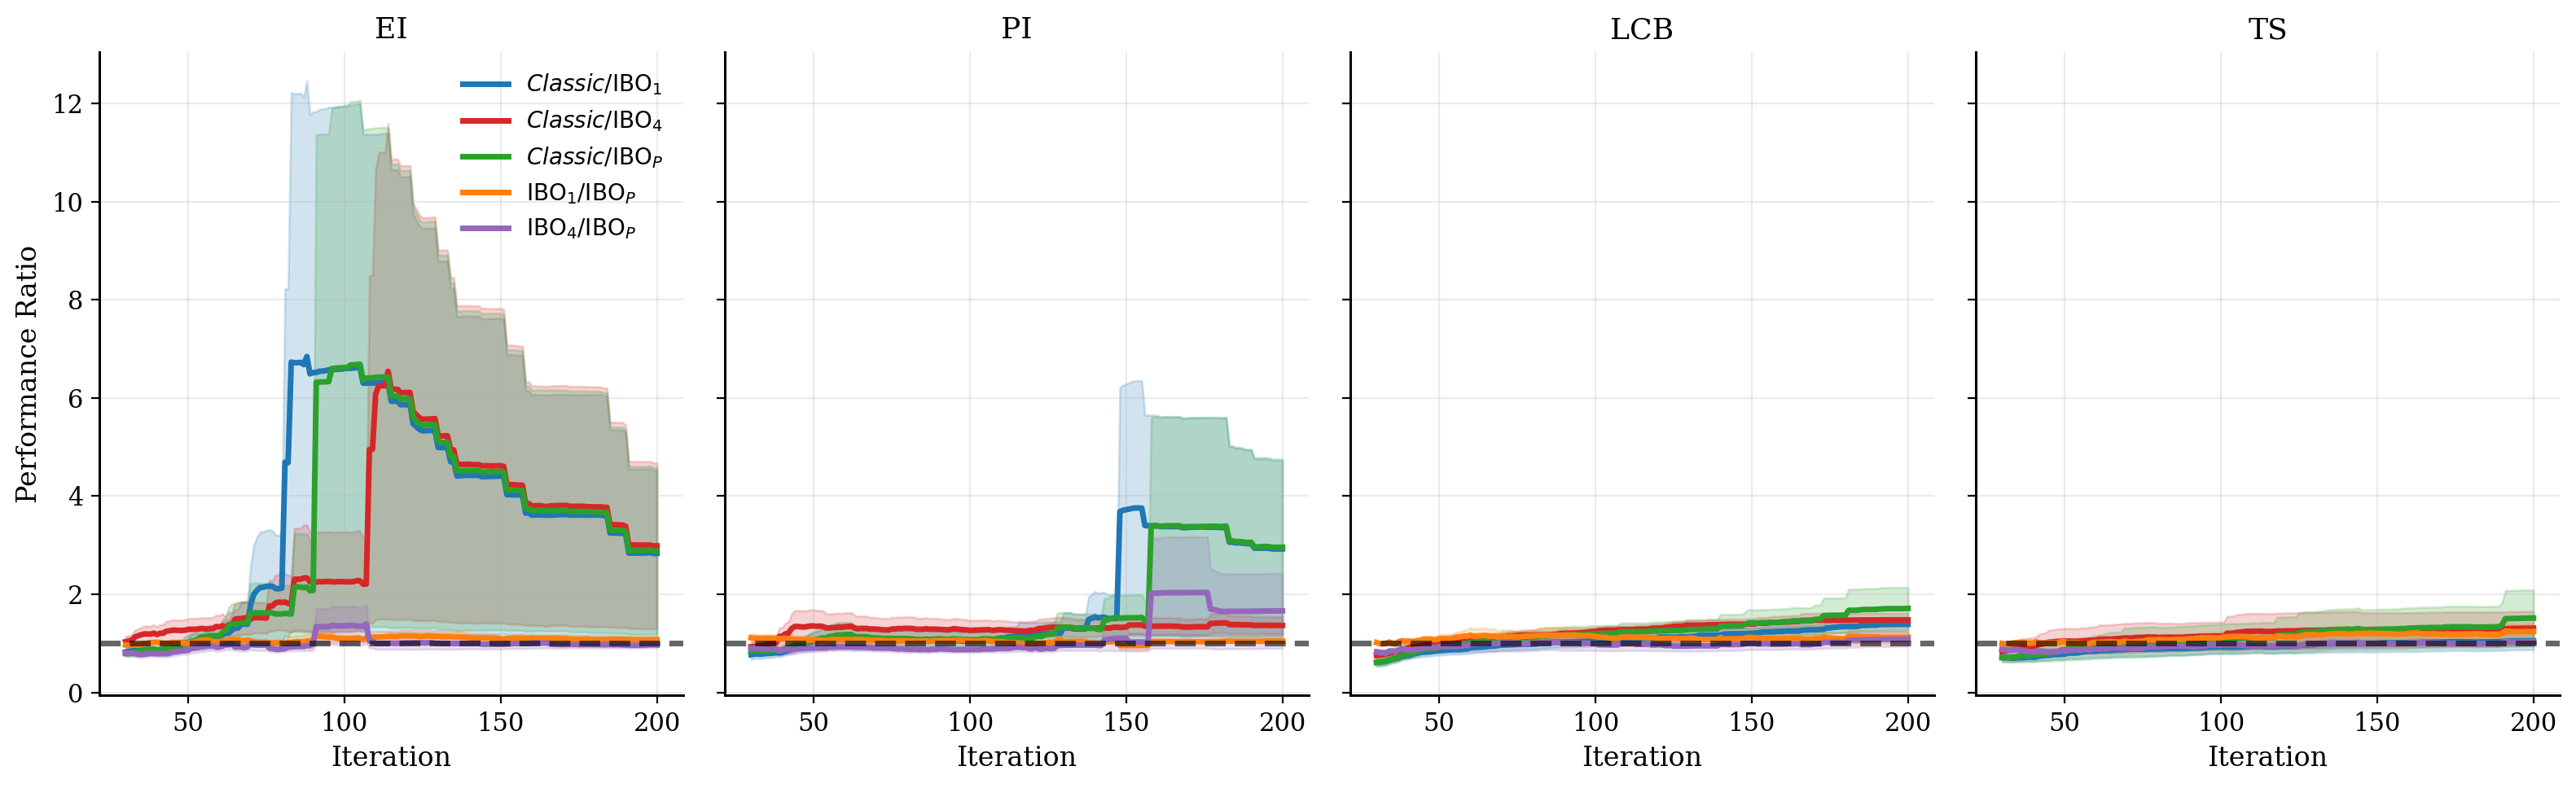

In [28]:
plot_mean_ratio_across_functions(all_histories_bench)


# Non-Stationary Samples

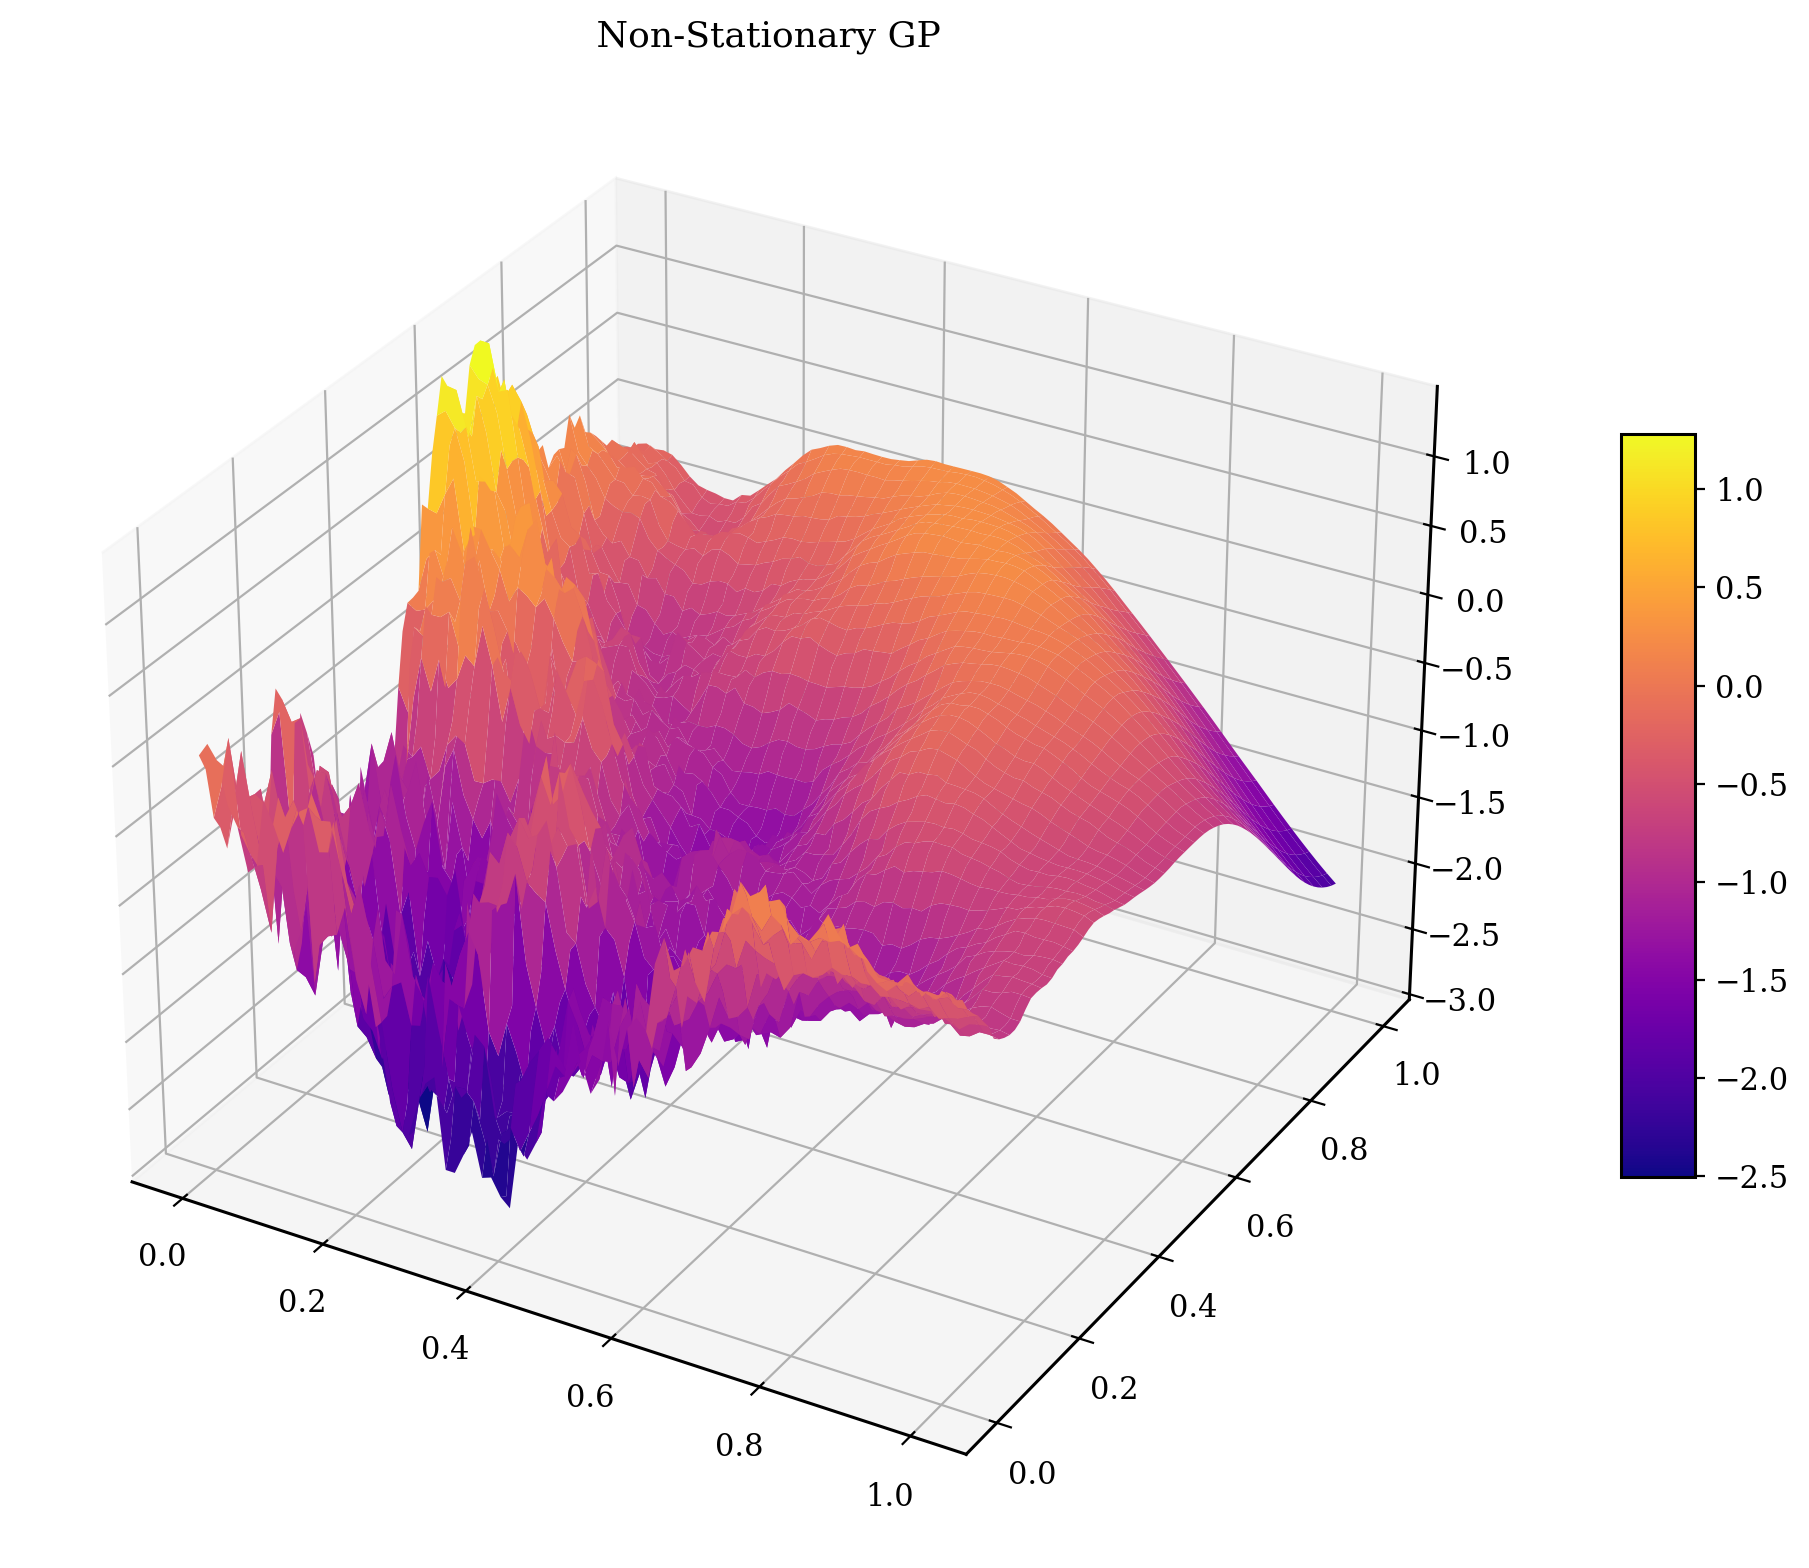

In [ ]:
def sample_gp_function_(seed=7):
    rng = np.random.default_rng(seed)

    # Domain grid
    n1 = 80 # Reduced slightly for memory/speed with 10k x 10k matrices
    x_line = np.linspace(0, 1, n1)
    X_m, Y_m = np.meshgrid(x_line, x_line)
    xs = np.column_stack([X_m.ravel(), Y_m.ravel()])
    nxs = xs.shape[0]

    # Calculate shared distance matrix
    D = cdist(xs, xs)

    # --- 1. JAGGED REGION (Matérn 1/2 / Exponential) ---
    # Rough, noisy appearance
    K_rough = np.exp(-D / 0.2)

    # --- 2. TRANSITIONAL REGION (Matérn 3/2) ---
    # Moderate smoothness
    sqrt3_D = np.sqrt(3) * D
    K_med = (1 + sqrt3_D / 0.4) * np.exp(-sqrt3_D / 0.4)

    # --- 3. SILKY REGION (RBF) ---
    # Very smooth
    K_smooth = np.exp(-(D**2) / (2 * 0.3**2))

    # --- SPATIAL WEIGHTING (The "Nasty" part) ---
    # We define weights that partition the unit square into different zones
    def get_weights(X):
        # Zone 1: Bottom Left (Rough)
        w1 = np.exp(-((X[:,0]-0.2)**2 + (X[:,1]-0.2)**2) / 0.1)
        # Zone 2: Top Right (Smooth)
        w2 = np.exp(-((X[:,0]-0.8)**2 + (X[:,1]-0.8)**2) / 0.1)
        # Zone 3: Middle Strip (Medium)
        w3 = np.exp(-((X[:,0]-0.5)**2 + (X[:,1]-0.5)**2) / 0.1)
        
        # Normalize weights so they sum to ~1 visually
        total = w1 + w2 + w3 
        return w1/total, w2/total, w3/total

    b1, b2, b3 = get_weights(xs)
    
    # Apply non-stationary construction: K = sum( w_i(x) * K_i * w_i(x') )
    # This ensures the covariance matrix remains positive definite
    K = np.outer(b1, b1) * K_rough + \
        np.outer(b2, b2) * K_smooth + \
        np.outer(b3, b3) * K_med

    # Numerical stability (Nugget)
    K += np.eye(nxs) * 1e-8

    # Sample using Cholesky
    L = np.linalg.cholesky(K)
    zs = L @ rng.standard_normal(nxs)
    Z2 = zs.reshape(n1, n1)

    f_interp = RegularGridInterpolator((x_line, x_line), Z2, bounds_error=False, fill_value=None)
    return f_interp, x_line, Z2
# Generate and Plot
f_nstat_1, x_coords, Z_vals = sample_gp_function_()
X_p, Y_p = np.meshgrid(x_coords, x_coords)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X_p, Y_p, Z_vals, cmap='plasma', lw=0, antialiased=True)

ax.set_title(" Non-Stationary GP")
plt.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
plt.tight_layout()
plt.savefig("f_nonstat.pdf", bbox_inches="tight", dpi=400)
plt.show()

--- Running 30 Seeds in Parallel for f_nstat_1 ---
Execution time: 146.7978 seconds


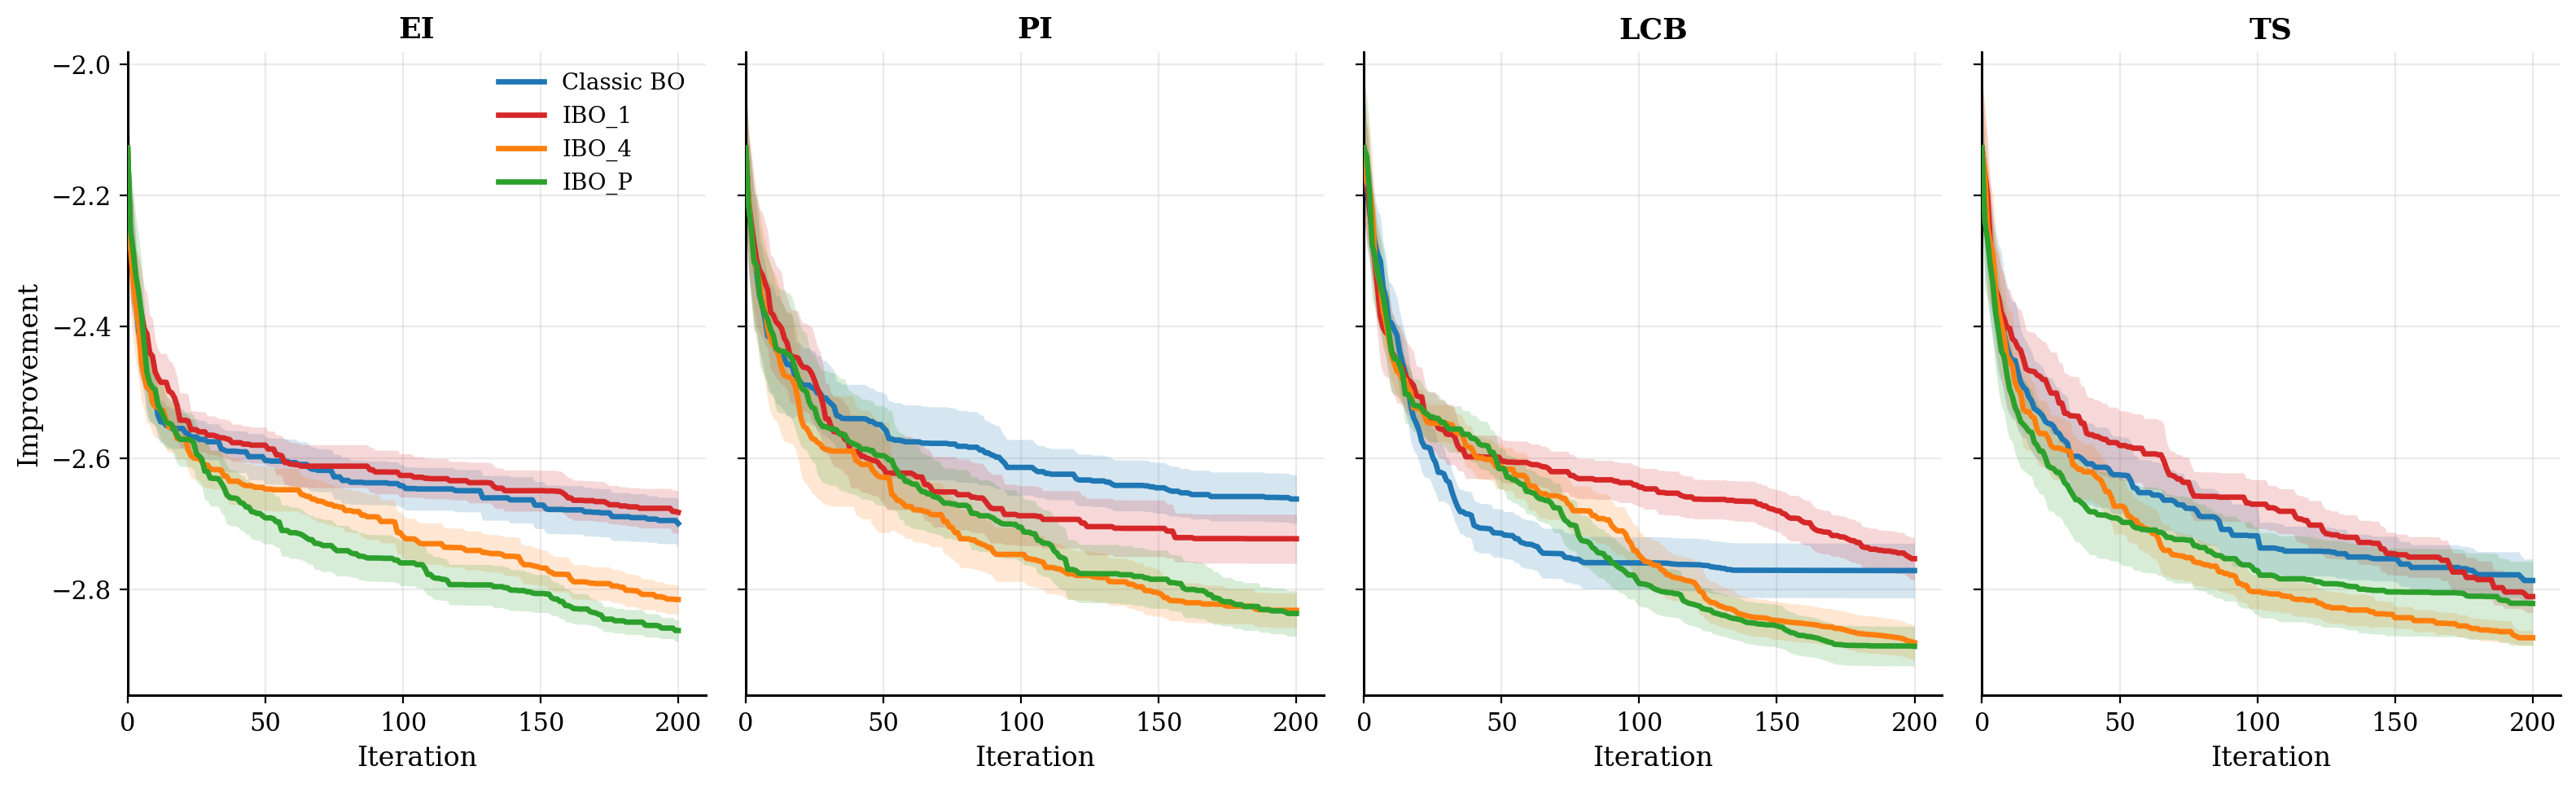

In [30]:

bounds = np.array([[0, 1], [0, 1]])
d = bounds.shape[0]
tree_depth = 3
n_init = 20*d
n_iter = 200
n_seeds = 30

kernel_args = {'l': 0.2, 'nu': 2.5}
noise_var = 1e-6
# 1. Define all configurations: (Label, n_parts, sig_on, acq_type, params)
configs = [
    # --- EI Group ---
    ("Classic BO - EI", 'fixed', 1,  False, 'ei', {'xi': 0.01}),
    ("IBO_1 - EI",     'fixed' , 1,  True,  'ei', {'xi': 0.01}),
    ("IBO_4 - EI",     'fixed' , 2,  True,  'ei', {'xi': 0.01}),
    ("IBO_P - EI",     'tree' , 2,  True,  'ei', {'xi': 0.01}),
    
    # --- PI Group ---
    ("Classic BO - PI",'fixed',  1,  False, 'pi', {'xi': 0.01}),
    ("IBO_1 - PI",     'fixed' , 1,  True,  'pi', {'xi': 0.01}),
    ("IBO_4 - PI",     'fixed' , 2,  True,  'pi', {'xi': 0.01}),
    ("IBO_P - PI",     'tree' ,  2,  True,  'pi', {'xi': 0.01}),
    
    # --- LCB Group ---
    ("Classic BO - LCB", 'fixed', 1,  False, 'lcb', {'beta': 3.0}),
    ("IBO_1 - LCB",      'fixed', 1,  True,  'lcb', {'beta': 3.0}),
    ("IBO_4 - LCB",     'fixed',  2,  True,  'lcb', {'beta': 3.0}),
    ("IBO_P - LCB",     'tree',    2, True,  'lcb', {'beta': 3.0}),
    
    # --- TS Group ---
    ("Classic BO - TS", 'fixed', 1,  False, 'ts', {}), # Fixed order
    ("IBO_1 - TS",     'fixed',  1,  True,  'ts', {}),
    ("IBO_4 - TS",     'fixed',  2, True,  'ts', {}),
    ("IBO_P - TS",     'tree',   2,  True,  'ts', {})
]

# Initialize storage
histories = {c[0]: np.zeros((n_seeds, n_iter + 1)) for c in configs}

start = time.perf_counter()
print(f"--- Running {n_seeds} Seeds in Parallel for f_nstat_1 ---")

# 2. Run parallel jobs using the unified worker function
results_nstat = Parallel(n_jobs=-1)(
    delayed(evaluate_single_bo)(
        seed, f_nstat_1, bounds, configs, n_init, d, n_iter, 
        kernel_args, noise_var, tree_depth, sigma_estimator, n_candidates=128
    ) for seed in range(n_seeds)
)

# 3. Reconstruct the histories dictionary from the parallel workers
for seed, seed_histories in results_nstat:
    for label, history in seed_histories.items():
        histories[label][seed, :] = history

end = time.perf_counter()
print(f"Execution time: {end - start:.4f} seconds")

# plot the results
plot_grouped_comparison(histories)

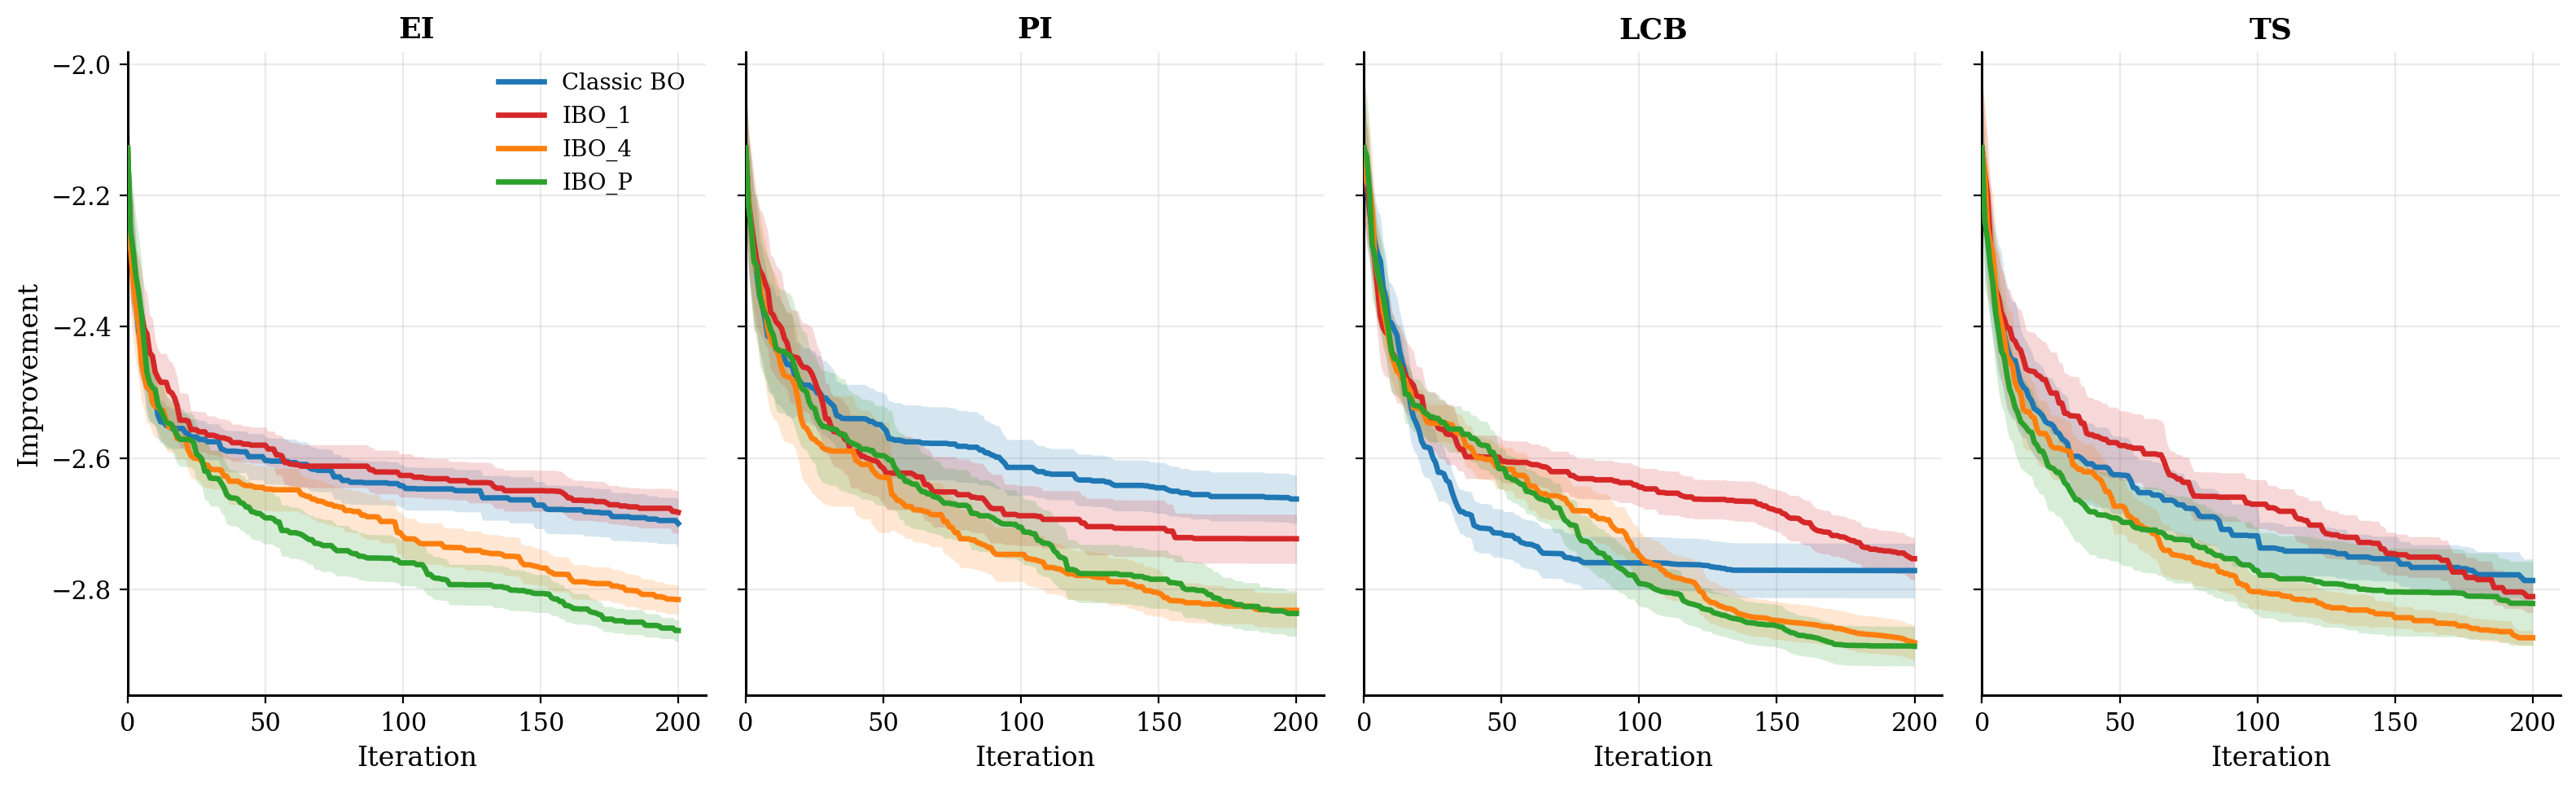

In [31]:
plot_grouped_comparison(histories)


# 10 Non stat

In [32]:
def sample_gp_function_(centers, seed=7):
    rng = np.random.default_rng(seed)

    # Domain grid
    n1 = 80
    x_line = np.linspace(0, 1, n1)
    X_m, Y_m = np.meshgrid(x_line, x_line)
    xs = np.column_stack([X_m.ravel(), Y_m.ravel()])
    nxs = xs.shape[0]

    # Distance matrix
    D = cdist(xs, xs)

    # --- Kernels (UNCHANGED) ---
    K_rough = np.exp(-D / 0.2)

    sqrt3_D = np.sqrt(3) * D
    K_med = (1 + sqrt3_D / 0.4) * np.exp(-sqrt3_D / 0.4)

    K_smooth = np.exp(-(D**2) / (2 * 0.3**2))

    # --- Spatial weights with movable centers ---
    def get_weights(X, centers):
        c1, c2, c3 = centers
        
        w1 = np.exp(-((X[:,0]-c1[0])**2 + (X[:,1]-c1[1])**2) / 0.1)
        w2 = np.exp(-((X[:,0]-c2[0])**2 + (X[:,1]-c2[1])**2) / 0.1)
        w3 = np.exp(-((X[:,0]-c3[0])**2 + (X[:,1]-c3[1])**2) / 0.1)

        total = w1 + w2 + w3 + 1e-6
        return w1/total, w2/total, w3/total

    b1, b2, b3 = get_weights(xs, centers)

    # Non-stationary covariance
    K = (
        np.outer(b1, b1) * K_rough +
        np.outer(b2, b2) * K_smooth +
        np.outer(b3, b3) * K_med
    )

    K += np.eye(nxs) * 1e-8

    L = np.linalg.cholesky(K)
    zs = L @ rng.standard_normal(nxs)
    Z2 = zs.reshape(n1, n1)

    f_interp = RegularGridInterpolator((x_line, x_line), Z2, bounds_error=False, fill_value=None)

    return f_interp, x_line, Z2

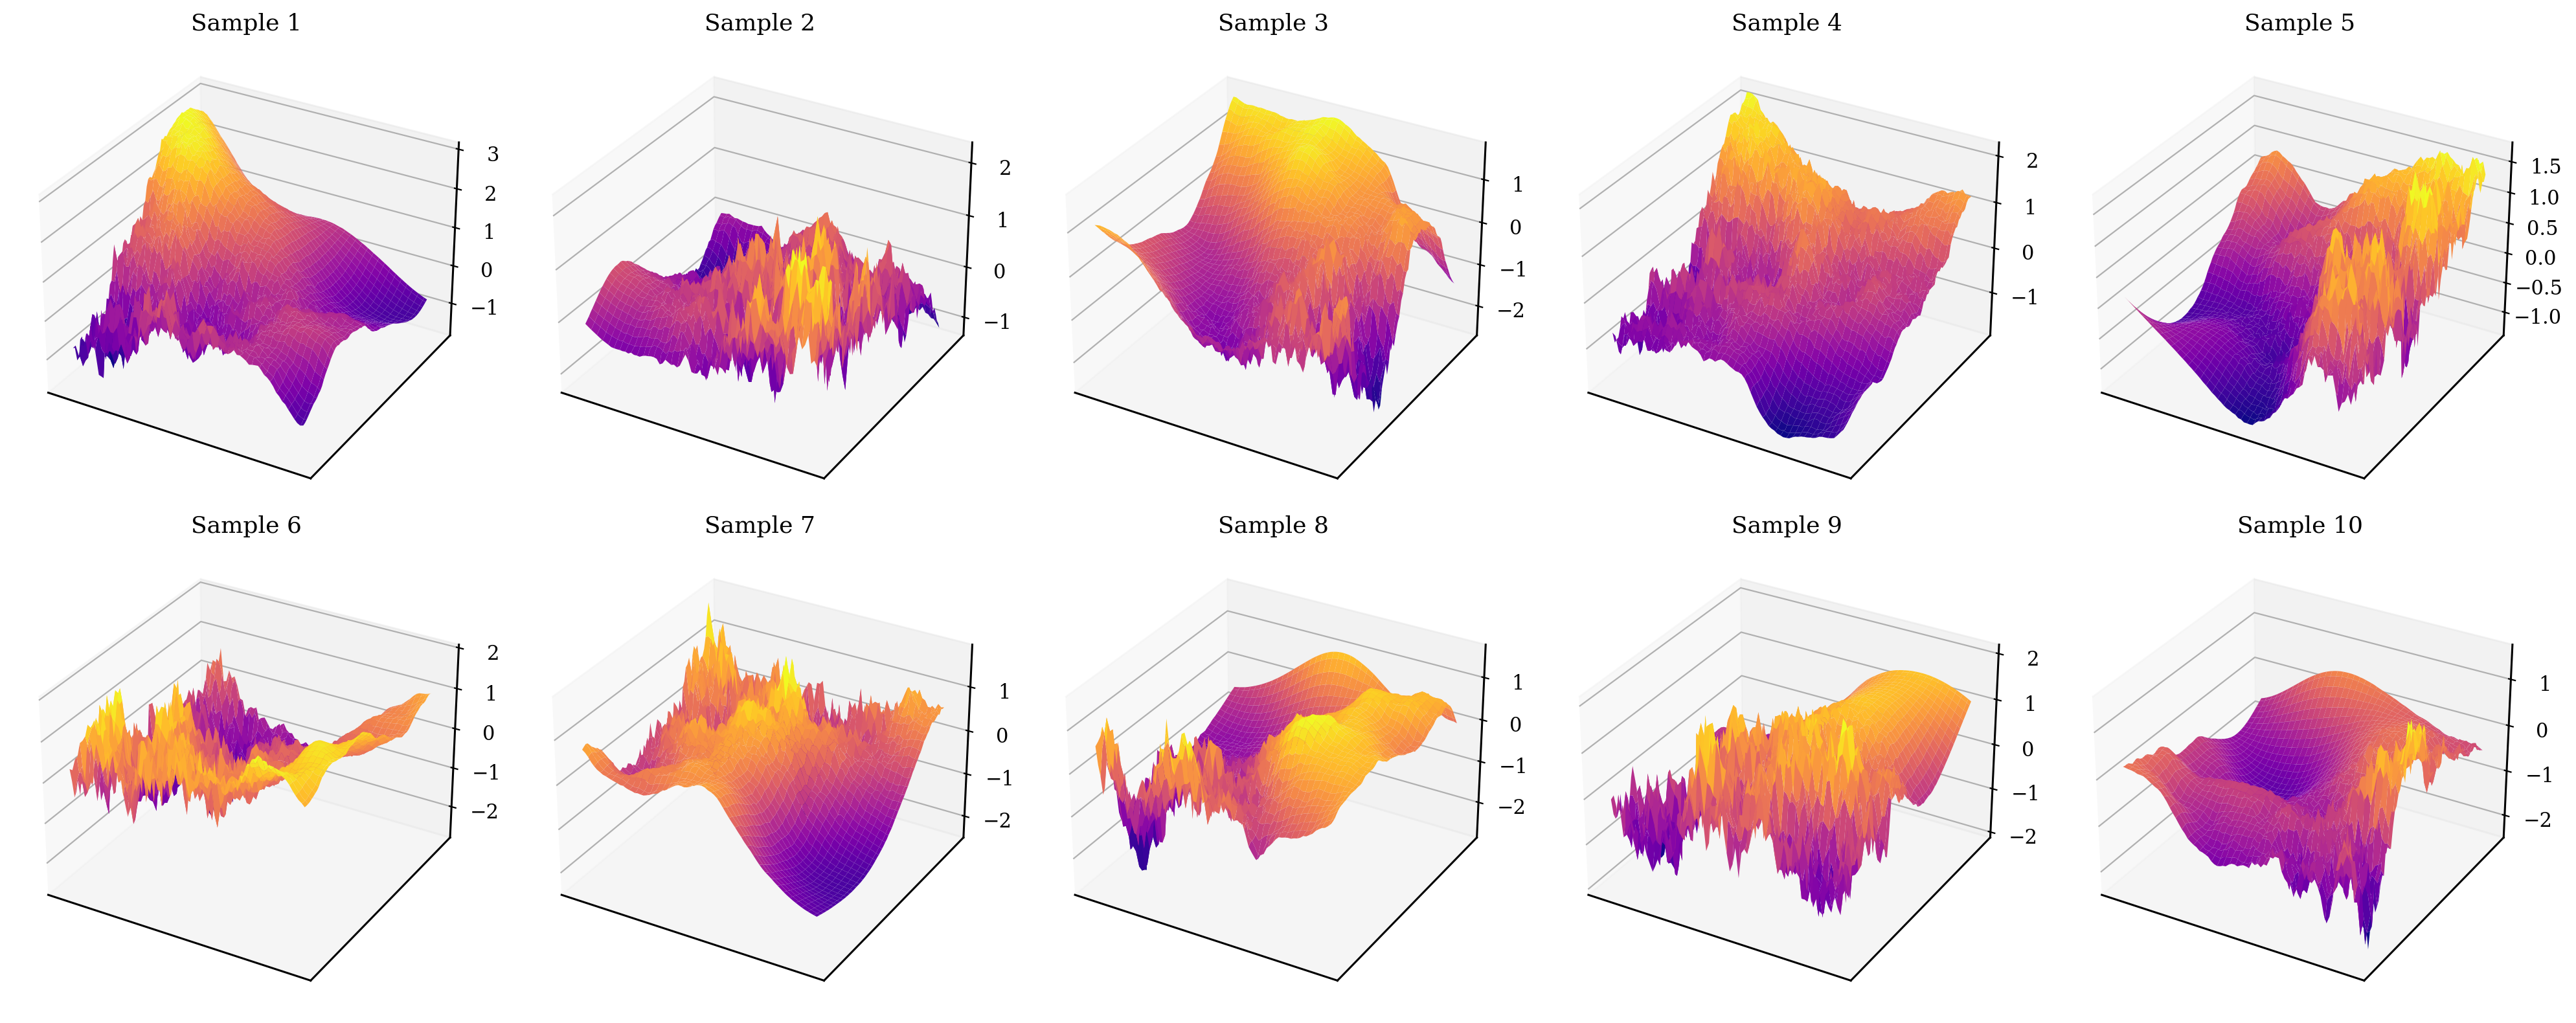

In [33]:
# --- Generate multiple functions with minimum distance between centers ---
def generate_centers(min_dist=0.3):
    while True:
        centers = np.random.uniform(0.1, 0.9, (3,2))
        pairwise_d = cdist(centers, centers)
        np.fill_diagonal(pairwise_d, np.inf)
        if np.all(pairwise_d >= min_dist):
            return centers

n_functions = 10
rows, cols = 2, 5
functions = {}

fig = plt.figure(figsize=(20, 8))

for i in range(n_functions):
    seed = random.randint(0, 1_000_000)
    centers = generate_centers(min_dist=0.3)  # Ensure minimum distance of 0.2

    f_val, x1s, Z2 = sample_gp_function_(centers, seed)
    functions[f"f_{i+1}"] = f_val

    X_plot, Y_plot = np.meshgrid(x1s, x1s)
    Z_plot = f_val(np.stack([X_plot, Y_plot], axis=-1))

    ax = fig.add_subplot(rows, cols, i + 1, projection='3d')
    ax.plot_surface(X_plot, Y_plot, Z_plot, cmap='plasma', linewidth=0)
    ax.set_title(f"Sample {i+1}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig("GP_samples_grid.pdf", bbox_inches="tight", dpi=400)
plt.show()


Running f_1 (1/10) in Parallel...

Running f_2 (2/10) in Parallel...

Running f_3 (3/10) in Parallel...

Running f_4 (4/10) in Parallel...

Running f_5 (5/10) in Parallel...

Running f_6 (6/10) in Parallel...

Running f_7 (7/10) in Parallel...

Running f_8 (8/10) in Parallel...

Running f_9 (9/10) in Parallel...

Running f_10 (10/10) in Parallel...
Execution time: 2984.5771 seconds


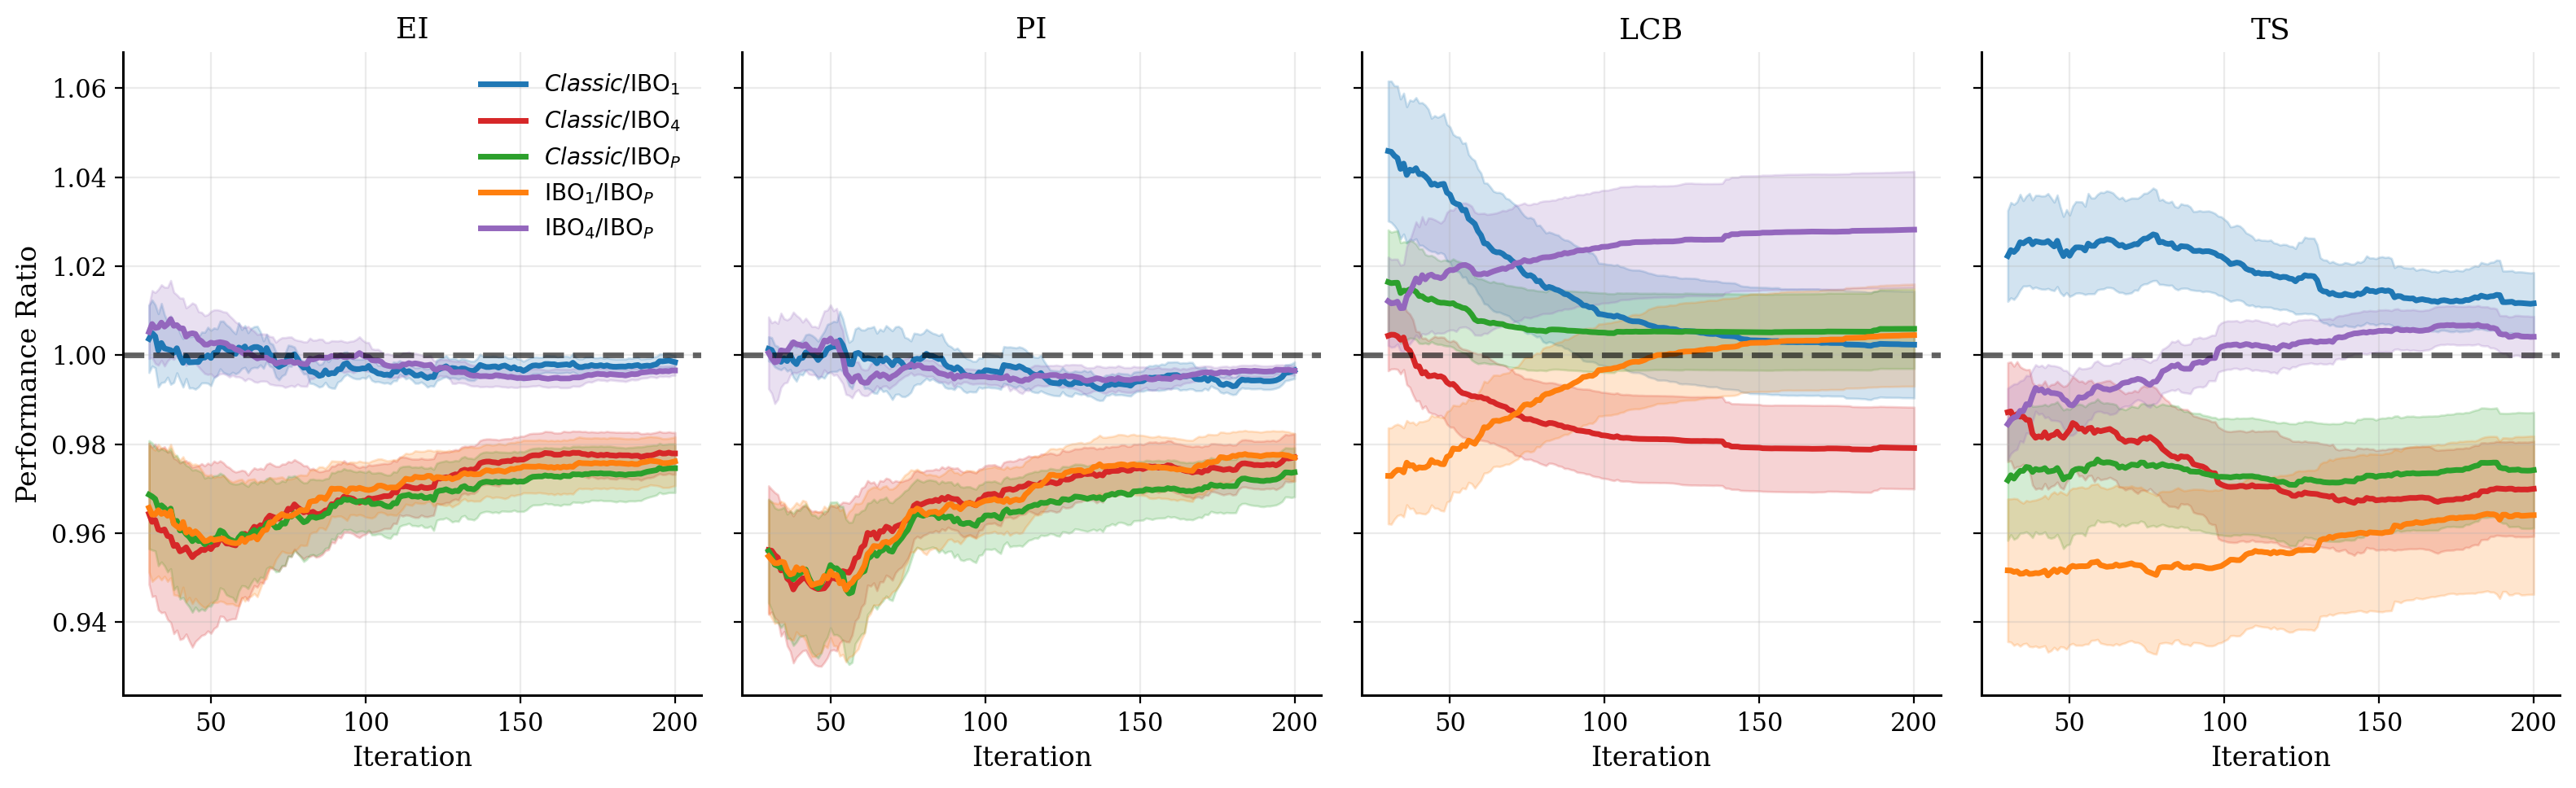

In [34]:


bounds_ = np.array([[0, 1], [0, 1]])
d = bounds_.shape[0]
tree_depth = 3
n_init = 20*d
n_iter = 200
n_seeds = 30

kernel_args = {'l': 0.2, 'nu': 2.5}
noise_var = 1e-6

# 1. Define all configurations: (Label, n_parts, sig_on, acq_type, params)
configs_ = [
    # --- EI Group ---
    ("Classic BO - EI", 'fixed', 1,  False, 'ei', {'xi': 0.05}),
    ("IBO_1 - EI",     'fixed' , 1,  True,  'ei', {'xi': 0.05}),
    ("IBO_4 - EI",     'fixed' , 2,  True,  'ei', {'xi': 0.05}),
    ("IBO_P - EI",     'tree' , 2,  True,  'ei', {'xi': 0.05}),
    
    # --- PI Group ---
    ("Classic BO - PI",'fixed',  1,  False, 'pi', {'xi': 0.05}),
    ("IBO_1 - PI",     'fixed' , 1,  True,  'pi', {'xi': 0.05}),
    ("IBO_4 - PI",     'fixed' , 2,  True,  'pi', {'xi': 0.05}),
    ("IBO_P - PI",     'tree' ,  2,  True,  'pi', {'xi': 0.05}),
    
    # --- LCB Group ---
    ("Classic BO - LCB", 'fixed', 1,  False, 'lcb', {'beta': 2.0}),
    ("IBO_1 - LCB",      'fixed', 1,  True,  'lcb', {'beta': 2.0}),
    ("IBO_4 - LCB",     'fixed',  2,  True,  'lcb', {'beta': 2.0}),
    ("IBO_P - LCB",     'tree',    2, True,  'lcb', {'beta': 2.0}),
    
    # --- TS Group ---
    ("Classic BO - TS", 'fixed', 1,  False, 'ts', {}), # Fixed order
    ("IBO_1 - TS",     'fixed',  1,  True,  'ts', {}),
    ("IBO_4 - TS",     'fixed',  2, True,  'ts', {}),
    ("IBO_P - TS",     'tree',   2,  True,  'ts', {})
]




all_histories_new = {}

start = time.perf_counter()

# Iterate over dictionary items
for f_id, (f_name, objective_function) in enumerate(functions.items()):
    
    print(f"\n==============================")
    print(f"Running {f_name} ({f_id+1}/{len(functions)}) in Parallel...")
    print(f"==============================")

    # Initialize histories for all configs
    histories_ = {c[0]: np.zeros((n_seeds, n_iter + 1)) for c in configs_}

    # 1. Run parallel jobs for the current objective function across all seeds
    results = Parallel(n_jobs=-1)(
        delayed(evaluate_single_bo)(
            seed, 
            objective_function, 
            bounds_, 
            configs_, 
            n_init, 
            d, 
            n_iter, 
            kernel_args, 
            noise_var, 
            tree_depth, 
            sigma_estimator, 
            n_candidates=128  # Matched to your snippet
        ) for seed in range(n_seeds)
    )

    # 2. Reconstruct the histories dictionary from the parallel workers
    for seed, seed_histories in results:
        for label, history in seed_histories.items():
            histories_[label][seed, :] = history

    all_histories_new[f_name] = histories_

end = time.perf_counter()

print(f"Execution time: {end - start:.4f} seconds")

# plot the results

plot_mean_ratio_across_functions(all_histories_new)


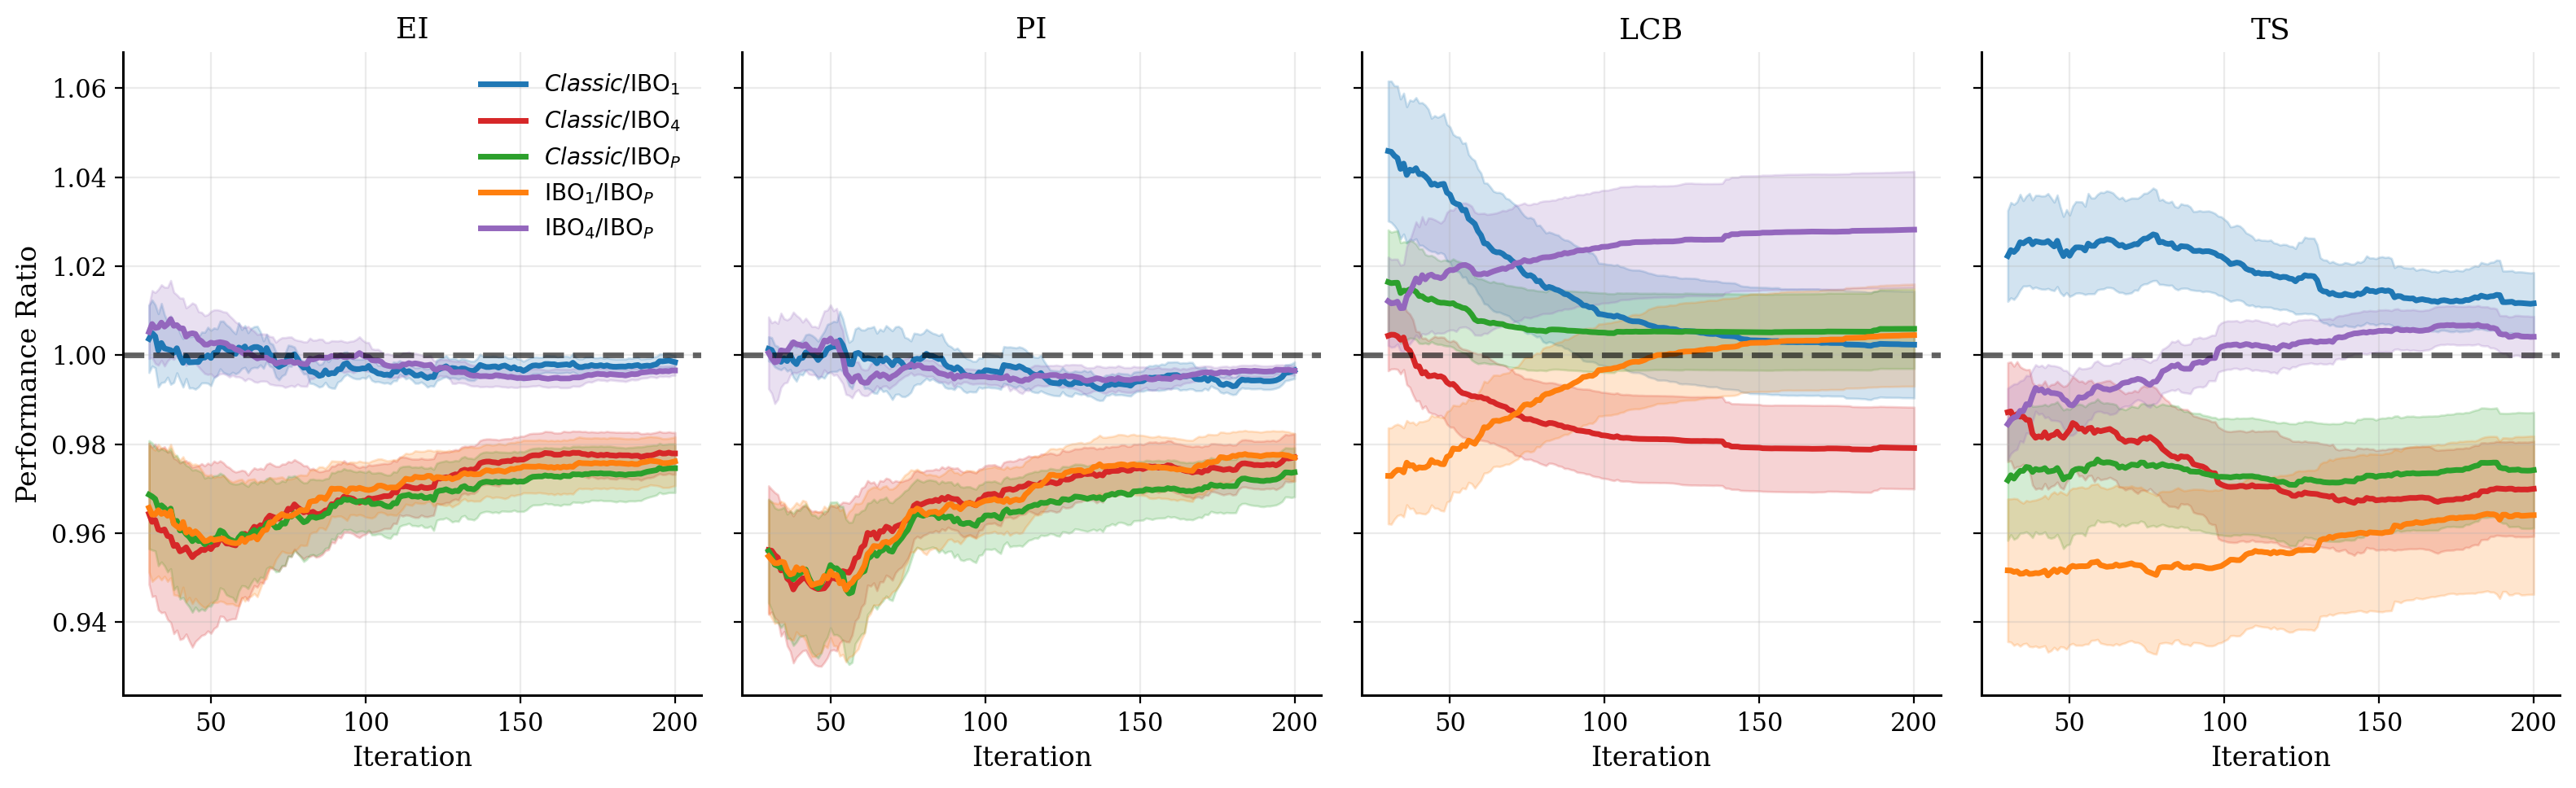

In [35]:
plot_mean_ratio_across_functions(all_histories_new)     
 